# Projet 01 — Analyse et nettoyage d'un jeu de données de ventes

## 1. Objectif

Ce projet consiste à explorer, auditer, nettoyer et analyser
un jeu de données commerciales afin de produire des données
fiables et exploitables.

## 2. Dataset

- Nom : Sample Superstore
- Source : fichier CSV
- Fichier : Sample - Superstore.csv

## 3. Démarche

1. Inspection initiale
2. Audit de la qualité des données
3. Définition des règles de nettoyage
4. Nettoyage et standardisation
5. Validation des données
6. Analyse exploratoire
7. Visualisation et interprétation
8. Documentation

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("Bibliothèques importées avec succès.")
print("Version de Pandas :", pd.__version__)
print("Version de NumPy :", np.__version__)

Bibliothèques importées avec succès.
Version de Pandas : 3.1.1
Version de NumPy : 2.5.4


In [2]:
# Chemin du projet
PROJECT_DIR = Path.cwd().parent

# Chemin du fichier CSV
DATA_PATH = PROJECT_DIR / "data" / "raw" / "Sample - Superstore.csv"

# Vérification
print("Dossier du projet :", PROJECT_DIR)
print("Fichier :", DATA_PATH)
print("Le fichier existe :", DATA_PATH.exists())

Dossier du projet : d:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis
Fichier : d:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\data\raw\Sample - Superstore.csv
Le fichier existe : True


## 4. Chargement du dataset

Le fichier CSV est chargé dans un DataFrame Pandas.

L'encodage Windows-1252 est spécifié explicitement afin
de garantir une lecture correcte des caractères.

In [3]:
# Chargement du dataset
df = pd.read_csv(DATA_PATH, encoding="cp1252")

# Confirmation du chargement
print("Dataset chargé avec succès.")
print("Type de l'objet :", type(df))

Dataset chargé avec succès.
Type de l'objet : <class 'pandas.DataFrame'>


In [4]:
# Dimensions du dataset
nb_lignes, nb_colonnes = df.shape

print("Nombre de lignes :", nb_lignes)
print("Nombre de colonnes :", nb_colonnes)

Nombre de lignes : 9994
Nombre de colonnes : 21


In [5]:
# Afficher les 5 premières lignes
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [6]:
# Afficher les 5 dernières lignes
df.tail()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9989,9990,CA-2014-110422,1/21/2014,1/23/2014,Second Class,TB-21400,Tom Boeckenhauer,Consumer,United States,Miami,...,33180,South,FUR-FU-10001889,Furniture,Furnishings,Ultra Door Pull Handle,25.248,3,0.2,4.1028
9990,9991,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,FUR-FU-10000747,Furniture,Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,0.0,15.6332
9991,9992,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.576,2,0.2,19.3932
9992,9993,CA-2017-121258,2/26/2017,3/3/2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,...,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,0.0,13.3200
9993,9994,CA-2017-119914,5/4/2017,5/9/2017,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,...,92683,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.160,2,0.0,72.9480


In [7]:
# Liste des colonnes
print("Colonnes du dataset :")

for i, colonne in enumerate(df.columns, start=1):
    print(f"{i}. {colonne}")

Colonnes du dataset :
1. Row ID
2. Order ID
3. Order Date
4. Ship Date
5. Ship Mode
6. Customer ID
7. Customer Name
8. Segment
9. Country
10. City
11. State
12. Postal Code
13. Region
14. Product ID
15. Category
16. Sub-Category
17. Product Name
18. Sales
19. Quantity
20. Discount
21. Profit


## 5. Inspection des types de données

Cette étape permet d'identifier le type technique attribué
à chaque colonne par Pandas.

L'objectif est de distinguer :
- les variables numériques ;
- les variables textuelles ;
- les variables temporelles ;
- les identifiants et codes.

Aucune conversion ne sera effectuée à ce stade.

In [8]:
# Examiner les types de données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [9]:
# Tableau récapitulatif des types
types_donnees = pd.DataFrame({
    "Colonne": df.columns,
    "Type": df.dtypes.astype(str).values,
    "Valeurs non nulles": df.count().values,
    "Valeurs manquantes": df.isna().sum().values
})

types_donnees

,Colonne,Type,Valeurs non nulles,Valeurs manquantes
0,Row ID,int64,9994,0
1,Order ID,str,9994,0
2,Order Date,str,9994,0
3,Ship Date,str,9994,0
4,Ship Mode,str,9994,0
5,Customer ID,str,9994,0
6,Customer Name,str,9994,0
7,Segment,str,9994,0
8,Country,str,9994,0
9,City,str,9994,0


In [10]:
# Statistiques descriptives des colonnes numériques
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [11]:
# Nombre de valeurs distinctes par colonne
valeurs_uniques = pd.DataFrame({
    "Colonne": df.columns,
    "Valeurs distinctes": df.nunique().values
})

valeurs_uniques

,Colonne,Valeurs distinctes
0,Row ID,9994
1,Order ID,5009
2,Order Date,1237
3,Ship Date,1334
4,Ship Mode,4
5,Customer ID,793
6,Customer Name,793
7,Segment,3
8,Country,1
9,City,531


In [12]:
# Vérifier l'unicité de Row ID
print("Nombre de Row ID distincts :", df["Row ID"].nunique())
print("Nombre total de lignes :", len(df))
print("Row ID tous uniques :", df["Row ID"].is_unique)

# Examiner les identifiants métier
print("Commandes distinctes :", df["Order ID"].nunique())
print("Clients distincts :", df["Customer ID"].nunique())
print("Produits distincts :", df["Product ID"].nunique())

Nombre de Row ID distincts : 9994
Nombre total de lignes : 9994
Row ID tous uniques : True
Commandes distinctes : 5009
Clients distincts : 793
Produits distincts : 1862


In [13]:
# Compter les lignes entièrement identiques
nombre_doublons_exacts = df.duplicated().sum()

print("Nombre de doublons exacts :", nombre_doublons_exacts)

Nombre de doublons exacts : 0


In [14]:
# Afficher les lignes potentiellement dupliquées
doublons = df[df.duplicated(keep=False)]

doublons.head(20)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit


## 6. Audit des valeurs catégorielles

L'objectif est d'identifier les différentes modalités présentes dans
les colonnes catégorielles et de vérifier leur fréquence.

Cette inspection permet notamment de repérer :
- des catégories inattendues ;
- des différences d'écriture ;
- des espaces superflus ;
- des valeurs incohérentes avec le domaine métier.

Aucune valeur ne sera modifiée à cette étape.

In [15]:
# Examiner les modalités et leurs fréquences
colonnes_categorielles = [
    "Ship Mode",
    "Segment",
    "Country",
    "Region",
    "Category",
    "Sub-Category"
]

for colonne in colonnes_categorielles:
    print(f"\n{'=' * 50}")
    print(f"Colonne : {colonne}")
    print(f"{'=' * 50}")
    print(df[colonne].value_counts(dropna=False))


Colonne : Ship Mode
Ship Mode
Standard Class    5968
Second Class      1945
First Class       1538
Same Day           543
Name: count, dtype: int64

Colonne : Segment
Segment
Consumer       5191
Corporate      3020
Home Office    1783
Name: count, dtype: int64

Colonne : Country
Country
United States    9994
Name: count, dtype: int64

Colonne : Region
Region
West       3203
East       2848
Central    2323
South      1620
Name: count, dtype: int64

Colonne : Category
Category
Office Supplies    6026
Furniture          2121
Technology         1847
Name: count, dtype: int64

Colonne : Sub-Category
Sub-Category
Binders        1523
Paper          1370
Furnishings     957
Phones          889
Storage         846
Art             796
Accessories     775
Chairs          617
Appliances      466
Labels          364
Tables          319
Envelopes       254
Bookcases       228
Fasteners       217
Supplies        190
Machines        115
Copiers          68
Name: count, dtype: int64


## 7. Audit des dates

Cette étape consiste à vérifier :
- si toutes les dates respectent le format attendu ;
- si certaines dates ne peuvent pas être interprétées ;
- si la date d'expédition est antérieure à la date de commande ;
- quelle est la période couverte par le dataset.

Les conversions seront réalisées dans des variables temporaires.
Le DataFrame original restera inchangé.

In [16]:
# Conversion temporaire des dates
dates_commande = pd.to_datetime(
    df["Order Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

dates_expedition = pd.to_datetime(
    df["Ship Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

# Vérifier les dates non interprétables
print("Dates de commande invalides :", dates_commande.isna().sum())
print("Dates d'expédition invalides :", dates_expedition.isna().sum())

# Examiner les périodes couvertes
print("\nPériode des commandes :")
print("Date minimale :", dates_commande.min())
print("Date maximale :", dates_commande.max())

print("\nPériode des expéditions :")
print("Date minimale :", dates_expedition.min())
print("Date maximale :", dates_expedition.max())

# Vérifier la chronologie commande / expédition
expedition_avant_commande = dates_expedition < dates_commande

print(
    "\nExpéditions antérieures aux commandes :",
    expedition_avant_commande.sum()
)

Dates de commande invalides : 0
Dates d'expédition invalides : 0

Période des commandes :
Date minimale : 2014-01-03 00:00:00
Date maximale : 2017-12-30 00:00:00

Période des expéditions :
Date minimale : 2014-01-07 00:00:00
Date maximale : 2018-01-05 00:00:00

Expéditions antérieures aux commandes : 0


In [17]:
# Nombre de noms associés à chaque identifiant de produit
produits_par_id = df.groupby("Product ID")["Product Name"].nunique()

# Nombre d'identifiants associés à chaque nom de produit
ids_par_nom = df.groupby("Product Name")["Product ID"].nunique()

# Nombre de noms associés à chaque identifiant client
clients_par_id = df.groupby("Customer ID")["Customer Name"].nunique()

# Nombre d'identifiants associés à chaque nom client
ids_par_client = df.groupby("Customer Name")["Customer ID"].nunique()

print("Identifiants de produits associés à plusieurs noms :",
      (produits_par_id > 1).sum())

print("Noms de produits associés à plusieurs identifiants :",
      (ids_par_nom > 1).sum())

print("Identifiants clients associés à plusieurs noms :",
      (clients_par_id > 1).sum())

print("Noms clients associés à plusieurs identifiants :",
      (ids_par_client > 1).sum())

Identifiants de produits associés à plusieurs noms : 32
Noms de produits associés à plusieurs identifiants : 16
Identifiants clients associés à plusieurs noms : 0
Noms clients associés à plusieurs identifiants : 0


In [18]:
print("Produits associés à plusieurs noms :")
display(produits_par_id[produits_par_id > 1])

print("\nNoms de produits associés à plusieurs identifiants :")
display(ids_par_nom[ids_par_nom > 1])

print("\nClients associés à plusieurs noms :")
display(clients_par_id[clients_par_id > 1])

print("\nNoms de clients associés à plusieurs identifiants :")
display(ids_par_client[ids_par_client > 1])

Produits associés à plusieurs noms :


Product ID
FUR-BO-10002213    2
FUR-CH-10001146    2
FUR-FU-10001473    2
FUR-FU-10004017    2
FUR-FU-10004091    2
FUR-FU-10004270    2
FUR-FU-10004848    2
FUR-FU-10004864    2
OFF-AP-10000576    2
OFF-AR-10001149    2
OFF-BI-10002026    2
OFF-BI-10004632    2
OFF-BI-10004654    2
OFF-PA-10000357    2
OFF-PA-10000477    2
OFF-PA-10000659    2
OFF-PA-10001166    2
OFF-PA-10001970    2
OFF-PA-10002195    2
OFF-PA-10002377    2
OFF-PA-10003022    2
OFF-ST-10001228    2
OFF-ST-10004950    2
TEC-AC-10002049    2
TEC-AC-10002550    2
TEC-AC-10003832    2
TEC-MA-10001148    2
TEC-PH-10001530    2
TEC-PH-10001795    2
TEC-PH-10002200    2
TEC-PH-10002310    2
TEC-PH-10004531    2
Name: Product Name, dtype: int64


Noms de produits associés à plusieurs identifiants :


Product Name
#10- 4 1/8" x 9 1/2" Recycled Envelopes           2
Avery Non-Stick Binders                           2
Easy-staple paper                                 8
Eldon Wave Desk Accessories                       2
KI Adjustable-Height Table                        2
Okidata C610n Printer                             2
Peel & Seel Recycled Catalog Envelopes, Brown     2
Prang Drawing Pencil Set                          2
Staple envelope                                   9
Staple holder                                     3
Staple magnet                                     2
Staple remover                                    3
Staple-based wall hangings                        2
Staples                                          10
Staples in misc. colors                           7
Storex Dura Pro Binders                           2
Name: Product ID, dtype: int64


Clients associés à plusieurs noms :


Series([], Name: Customer Name, dtype: int64)


Noms de clients associés à plusieurs identifiants :


Series([], Name: Customer ID, dtype: int64)

In [19]:
# Informations qui devraient rester cohérentes pour une commande
colonnes_commande = [
    "Customer ID",
    "Order Date",
    "Ship Date",
    "Ship Mode"
]

for colonne in colonnes_commande:
    variations = df.groupby("Order ID")[colonne].nunique()

    anomalies = variations[variations > 1]

    print(
        f"{colonne} :",
        len(anomalies),
        "commandes avec plusieurs valeurs distinctes"
    )

Customer ID : 0 commandes avec plusieurs valeurs distinctes
Order Date : 0 commandes avec plusieurs valeurs distinctes
Ship Date : 0 commandes avec plusieurs valeurs distinctes
Ship Mode : 0 commandes avec plusieurs valeurs distinctes


In [20]:
# Examiner les répétitions de couples commande-produit
doublons_commande_produit = df.duplicated(
    subset=["Order ID", "Product ID"],
    keep=False
)

print(
    "Lignes concernées par une répétition du couple "
    "Order ID / Product ID :",
    doublons_commande_produit.sum()
)

display(
    df.loc[
        doublons_commande_produit,
        ["Order ID", "Product ID", "Product Name",
         "Sales", "Quantity", "Discount", "Profit"]
    ].sort_values(["Order ID", "Product ID"])
)

Lignes concernées par une répétition du couple Order ID / Product ID : 16


,Order ID,Product ID,Product Name,Sales,Quantity,Discount,Profit
6498,CA-2015-103135,OFF-BI-10000069,"GBC Prepunched Paper, 19-Hole, for Binding Sys...",135.090,9,0.0,62.1414
6500,CA-2015-103135,OFF-BI-10000069,"GBC Prepunched Paper, 19-Hole, for Binding Sys...",90.060,6,0.0,41.4276
350,CA-2016-129714,OFF-PA-10001970,Xerox 1881,24.560,2,0.0,11.5432
352,CA-2016-129714,OFF-PA-10001970,Xerox 1881,49.120,4,0.0,23.0864
1300,CA-2016-137043,FUR-FU-10003664,"Electrix Architect's Clamp-On Swing Arm Lamp, ...",572.760,6,0.0,166.1004
1301,CA-2016-137043,FUR-FU-10003664,"Electrix Architect's Clamp-On Swing Arm Lamp, ...",286.380,3,0.0,83.0502
9168,CA-2016-140571,OFF-PA-10001954,Xerox 1964,319.760,14,0.0,147.0896
9169,CA-2016-140571,OFF-PA-10001954,Xerox 1964,45.680,2,0.0,21.0128
7881,CA-2017-118017,TEC-AC-10002006,Memorex Micro Travel Drive 16 GB,76.752,6,0.2,10.5534
7882,CA-2017-118017,TEC-AC-10002006,Memorex Micro Travel Drive 16 GB,102.336,8,0.2,14.0712


In [21]:
# Afficher toutes les colonnes des lignes concernées
lignes_repetitions = df.loc[doublons_commande_produit].copy()

with pd.option_context("display.max_columns", None):
    display(lignes_repetitions)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
350,351,CA-2016-129714,9/1/2016,9/3/2016,First Class,AB-10060,Adam Bellavance,Home Office,United States,New York City,New York,10009,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,24.560,2,0.0,11.5432
352,353,CA-2016-129714,9/1/2016,9/3/2016,First Class,AB-10060,Adam Bellavance,Home Office,United States,New York City,New York,10009,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,49.120,4,0.0,23.0864
430,431,US-2016-123750,4/15/2016,4/21/2016,Standard Class,RB-19795,Ross Baird,Home Office,United States,Gastonia,North Carolina,28052,South,TEC-AC-10004659,Technology,Accessories,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,408.744,7,0.2,76.6395
431,432,US-2016-123750,4/15/2016,4/21/2016,Standard Class,RB-19795,Ross Baird,Home Office,United States,Gastonia,North Carolina,28052,South,TEC-AC-10004659,Technology,Accessories,Imation Secure+ Hardware Encrypted USB 2.0 Fla...,291.960,5,0.2,54.7425
1300,1301,CA-2016-137043,12/23/2016,12/25/2016,Second Class,LC-17140,Logan Currie,Consumer,United States,Springfield,Virginia,22153,South,FUR-FU-10003664,Furniture,Furnishings,"Electrix Architect's Clamp-On Swing Arm Lamp, ...",572.760,6,0.0,166.1004
1301,1302,CA-2016-137043,12/23/2016,12/25/2016,Second Class,LC-17140,Logan Currie,Consumer,United States,Springfield,Virginia,22153,South,FUR-FU-10003664,Furniture,Furnishings,"Electrix Architect's Clamp-On Swing Arm Lamp, ...",286.380,3,0.0,83.0502
3183,3184,CA-2017-152912,11/9/2017,11/12/2017,Second Class,BM-11650,Brian Moss,Corporate,United States,Columbia,Maryland,21044,East,OFF-ST-10003208,Office Supplies,Storage,Adjustable Depth Letter/Legal Cart,1633.140,9,0.0,473.6106
3184,3185,CA-2017-152912,11/9/2017,11/12/2017,Second Class,BM-11650,Brian Moss,Corporate,United States,Columbia,Maryland,21044,East,OFF-ST-10003208,Office Supplies,Storage,Adjustable Depth Letter/Legal Cart,544.380,3,0.0,157.8702
3405,3406,US-2014-150119,4/23/2014,4/27/2014,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588
3406,3407,US-2014-150119,4/23/2014,4/27/2014,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,Ohio,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588


In [22]:
# Examiner précisément les deux lignes suspectes
df.loc[
    df["Row ID"].isin([3406, 3407])
].T

,3405,3406
Row ID,3406,3407
Order ID,US-2014-150119,US-2014-150119
Order Date,4/23/2014,4/23/2014
Ship Date,4/27/2014,4/27/2014
Ship Mode,Standard Class,Standard Class
Customer ID,LB-16795,LB-16795
Customer Name,Laurel Beltran,Laurel Beltran
Segment,Home Office,Home Office
Country,United States,United States
City,Columbus,Columbus


### Résultat : répétition de lignes métier

Une paire de lignes a été identifiée avec des valeurs identiques sur
les 20 colonnes métier.

Les deux lignes concernées sont :
- Row ID 3406
- Row ID 3407

Elles possèdent le même Order ID, le même Product ID et les mêmes
valeurs commerciales.

Seul le Row ID diffère.

Cette paire est considérée comme un doublon métier potentiel confirmé
sur les données disponibles.

Aucune ligne n'est supprimée pendant cette phase d'audit.
Le traitement sera décidé pendant la phase de nettoyage.

In [23]:
# Contrôle des valeurs numériques
colonnes_numeriques = ["Sales", "Quantity", "Discount", "Profit"]

for colonne in colonnes_numeriques:
    print(f"\n--- {colonne} ---")
    print("Valeurs négatives :", (df[colonne] < 0).sum())
    print("Valeurs nulles     :", (df[colonne] == 0).sum())
    print("Valeurs positives  :", (df[colonne] > 0).sum())
    print("Valeurs manquantes :", df[colonne].isna().sum())


--- Sales ---
Valeurs négatives : 0
Valeurs nulles     : 0
Valeurs positives  : 9994
Valeurs manquantes : 0

--- Quantity ---
Valeurs négatives : 0
Valeurs nulles     : 0
Valeurs positives  : 9994
Valeurs manquantes : 0

--- Discount ---
Valeurs négatives : 0
Valeurs nulles     : 4798
Valeurs positives  : 5196
Valeurs manquantes : 0

--- Profit ---
Valeurs négatives : 1871
Valeurs nulles     : 65
Valeurs positives  : 8058
Valeurs manquantes : 0


In [24]:
# Vérification du domaine des remises
print("Minimum Discount :", df["Discount"].min())
print("Maximum Discount :", df["Discount"].max())
print("Valeurs distinctes de Discount :")
print(sorted(df["Discount"].unique()))

# Vérification des quantités non entières
quantites_non_entieres = (
    df["Quantity"] % 1 != 0
).sum()

print("\nQuantités non entières :", quantites_non_entieres)

Minimum Discount : 0.0
Maximum Discount : 0.8
Valeurs distinctes de Discount :
[np.float64(0.0), np.float64(0.1), np.float64(0.15), np.float64(0.2), np.float64(0.3), np.float64(0.32), np.float64(0.4), np.float64(0.45), np.float64(0.5), np.float64(0.6), np.float64(0.7), np.float64(0.8)]

Quantités non entières : 0


In [25]:
# Examiner les 10 valeurs les plus élevées et les plus faibles

print("=== 10 ventes les plus élevées ===")
display(df.nlargest(10, "Sales")[["Order ID", "Product Name", "Sales", "Quantity", "Discount", "Profit"]])

print("\n=== 10 bénéfices les plus faibles ===")
display(df.nsmallest(10, "Profit")[["Order ID", "Product Name", "Sales", "Quantity", "Discount", "Profit"]])

=== 10 ventes les plus élevées ===


,Order ID,Product Name,Sales,Quantity,Discount,Profit
2697,CA-2014-145317,Cisco TelePresence System EX90 Videoconferenci...,22638.480,6,0.5,-1811.0784
6826,CA-2016-118689,Canon imageCLASS 2200 Advanced Copier,17499.950,5,0.0,8399.9760
8153,CA-2017-140151,Canon imageCLASS 2200 Advanced Copier,13999.960,4,0.0,6719.9808
2623,CA-2017-127180,Canon imageCLASS 2200 Advanced Copier,11199.968,4,0.2,3919.9888
4190,CA-2017-166709,Canon imageCLASS 2200 Advanced Copier,10499.970,3,0.0,5039.9856
9039,CA-2016-117121,GBC Ibimaster 500 Manual ProClick Binding System,9892.740,13,0.0,4946.3700
4098,CA-2014-116904,Ibico EPK-21 Electric Binding System,9449.950,5,0.0,4630.4755
4277,US-2016-107440,"3D Systems Cube Printer, 2nd Generation, Magenta",9099.930,7,0.0,2365.9818
8488,CA-2016-158841,HP Designjet T520 Inkjet Large Format Printer ...,8749.950,5,0.0,2799.9840
6425,CA-2016-143714,Canon imageCLASS 2200 Advanced Copier,8399.976,4,0.4,1119.9968



=== 10 bénéfices les plus faibles ===


,Order ID,Product Name,Sales,Quantity,Discount,Profit
7772,CA-2016-108196,Cubify CubeX 3D Printer Double Head Print,4499.985,5,0.7,-6599.9780
683,US-2017-168116,Cubify CubeX 3D Printer Triple Head Print,7999.980,4,0.5,-3839.9904
9774,CA-2014-169019,GBC DocuBind P400 Electric Binding System,2177.584,8,0.8,-3701.8928
3011,CA-2017-134845,Lexmark MX611dhe Monochrome Laser Printer,2549.985,5,0.7,-3399.9800
4991,US-2017-122714,Ibico EPK-21 Electric Binding System,1889.990,5,0.8,-2929.4845
3151,CA-2015-147830,Cubify CubeX 3D Printer Double Head Print,1799.994,2,0.7,-2639.9912
5310,CA-2017-131254,Fellowes PB500 Electric Punch Plastic Comb Bin...,1525.188,6,0.8,-2287.7820
9639,CA-2015-116638,Chromcraft Bull-Nose Wood Oval Conference Tabl...,4297.644,13,0.4,-1862.3124
1199,CA-2016-130946,GBC DocuBind P400 Electric Binding System,1088.792,4,0.8,-1850.9464
2697,CA-2014-145317,Cisco TelePresence System EX90 Videoconferenci...,22638.480,6,0.5,-1811.0784


In [26]:
# Détection statistique des valeurs extrêmes avec la méthode IQR

for colonne in ["Sales", "Profit"]:
    Q1 = df[colonne].quantile(0.25)
    Q3 = df[colonne].quantile(0.75)

    IQR = Q3 - Q1

    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    valeurs_extremes = df[
        (df[colonne] < borne_inf) |
        (df[colonne] > borne_sup)
    ]

    print(f"\n--- {colonne} ---")
    print("Q1 :", Q1)
    print("Q3 :", Q3)
    print("IQR :", IQR)
    print("Borne inférieure :", borne_inf)
    print("Borne supérieure :", borne_sup)
    print("Nombre de valeurs extrêmes :", len(valeurs_extremes))


--- Sales ---
Q1 : 17.28
Q3 : 209.94
IQR : 192.66
Borne inférieure : -271.71000000000004
Borne supérieure : 498.93
Nombre de valeurs extrêmes : 1167

--- Profit ---
Q1 : 1.72875
Q3 : 29.364
IQR : 27.63525
Borne inférieure : -39.724125
Borne supérieure : 70.816875
Nombre de valeurs extrêmes : 1881


In [27]:
# Répartition des valeurs extrêmes par rapport aux bornes IQR

for colonne in ["Sales", "Profit"]:
    Q1 = df[colonne].quantile(0.25)
    Q3 = df[colonne].quantile(0.75)
    IQR = Q3 - Q1

    borne_inf = Q1 - 1.5 * IQR
    borne_sup = Q3 + 1.5 * IQR

    inferieures = (df[colonne] < borne_inf).sum()
    superieures = (df[colonne] > borne_sup).sum()

    print(f"\n--- {colonne} ---")
    print("Valeurs sous la borne inférieure :", inferieures)
    print("Valeurs au-dessus de la borne supérieure :", superieures)
    print("Total :", inferieures + superieures)


--- Sales ---
Valeurs sous la borne inférieure : 0
Valeurs au-dessus de la borne supérieure : 1167
Total : 1167

--- Profit ---
Valeurs sous la borne inférieure : 604
Valeurs au-dessus de la borne supérieure : 1277
Total : 1881


In [28]:
# Calcul du prix unitaire implicite
prix_unitaire = df["Sales"] / (
    df["Quantity"] * (1 - df["Discount"])
)

print("Prix unitaires manquants :", prix_unitaire.isna().sum())
print("Prix unitaires infinis :", np.isinf(prix_unitaire).sum())
print("Prix unitaires nuls :", (prix_unitaire == 0).sum())
print("Prix unitaires négatifs :", (prix_unitaire < 0).sum())

print("\nStatistiques du prix unitaire :")
display(prix_unitaire.describe())

Prix unitaires manquants : 0
Prix unitaires infinis : 0
Prix unitaires nuls : 0
Prix unitaires négatifs : 0

Statistiques du prix unitaire :


count    9994.000000
mean       75.571127
std       188.961461
min         0.990000
25%         6.480000
50%        19.980000
75%        76.980000
max      7546.160000
dtype: float64

PHASE 3

In [29]:
# Identifier les Product ID associés à plusieurs noms

produits_incoherents = (
    df.groupby("Product ID")["Product Name"]
    .nunique()
)

produits_incoherents = produits_incoherents[
    produits_incoherents > 1
]

print("Nombre de Product ID concernés :", len(produits_incoherents))

display(produits_incoherents)

Nombre de Product ID concernés : 32


Product ID
FUR-BO-10002213    2
FUR-CH-10001146    2
FUR-FU-10001473    2
FUR-FU-10004017    2
FUR-FU-10004091    2
FUR-FU-10004270    2
FUR-FU-10004848    2
FUR-FU-10004864    2
OFF-AP-10000576    2
OFF-AR-10001149    2
OFF-BI-10002026    2
OFF-BI-10004632    2
OFF-BI-10004654    2
OFF-PA-10000357    2
OFF-PA-10000477    2
OFF-PA-10000659    2
OFF-PA-10001166    2
OFF-PA-10001970    2
OFF-PA-10002195    2
OFF-PA-10002377    2
OFF-PA-10003022    2
OFF-ST-10001228    2
OFF-ST-10004950    2
TEC-AC-10002049    2
TEC-AC-10002550    2
TEC-AC-10003832    2
TEC-MA-10001148    2
TEC-PH-10001530    2
TEC-PH-10001795    2
TEC-PH-10002200    2
TEC-PH-10002310    2
TEC-PH-10004531    2
Name: Product Name, dtype: int64

In [30]:
# Afficher les noms associés aux Product ID incohérents

details_produits = df[
    df["Product ID"].isin(produits_incoherents.index)
][["Product ID", "Product Name"]].drop_duplicates()

details_produits = details_produits.sort_values(
    by=["Product ID", "Product Name"]
)

display(details_produits.to_string(index=False))

'     Product ID                                                                                    Product Name\nFUR-BO-10002213                                                           DMI Eclipse Executive Suite Bookcases\nFUR-BO-10002213                                                Sauder Forest Hills Library, Woodland Oak Finish\nFUR-CH-10001146                                                                        Global Task Chair, Black\nFUR-CH-10001146                                                     Global Value Mid-Back Manager\'s Chair, Gray\nFUR-FU-10001473                                                                         DAX Wood Document Frame\nFUR-FU-10001473                                          Eldon Executive Woodline II Desk Accessories, Mahogany\nFUR-FU-10004017                                                   Executive Impressions 13" Chairman Wall Clock\nFUR-FU-10004017         Tenex Contemporary Contur Chairmats for Low and Medium Pile Carpet, Co

In [31]:
# Examiner les catégories et sous-catégories
# associées aux 32 identifiants concernés

details_categories = df[
    df["Product ID"].isin(produits_incoherents.index)
][
    ["Product ID", "Product Name", "Category", "Sub-Category"]
].drop_duplicates()

details_categories = details_categories.sort_values(
    by=["Product ID", "Product Name"]
)

display(details_categories.to_string(index=False))

'     Product ID                                                                                    Product Name        Category Sub-Category\nFUR-BO-10002213                                                           DMI Eclipse Executive Suite Bookcases       Furniture    Bookcases\nFUR-BO-10002213                                                Sauder Forest Hills Library, Woodland Oak Finish       Furniture    Bookcases\nFUR-CH-10001146                                                                        Global Task Chair, Black       Furniture       Chairs\nFUR-CH-10001146                                                     Global Value Mid-Back Manager\'s Chair, Gray       Furniture       Chairs\nFUR-FU-10001473                                                                         DAX Wood Document Frame       Furniture  Furnishings\nFUR-FU-10001473                                          Eldon Executive Woodline II Desk Accessories, Mahogany       Furniture  Furnishings\nFUR-

In [32]:
noms_incoherents = (
    df.groupby("Product Name")["Product ID"]
    .nunique()
)

noms_incoherents = noms_incoherents[noms_incoherents > 1]

display(noms_incoherents)

Product Name
#10- 4 1/8" x 9 1/2" Recycled Envelopes           2
Avery Non-Stick Binders                           2
Easy-staple paper                                 8
Eldon Wave Desk Accessories                       2
KI Adjustable-Height Table                        2
Okidata C610n Printer                             2
Peel & Seel Recycled Catalog Envelopes, Brown     2
Prang Drawing Pencil Set                          2
Staple envelope                                   9
Staple holder                                     3
Staple magnet                                     2
Staple remover                                    3
Staple-based wall hangings                        2
Staples                                          10
Staples in misc. colors                           7
Storex Dura Pro Binders                           2
Name: Product ID, dtype: int64

In [33]:
print("df existe :", "df" in globals())

df existe : True


In [34]:
import pandas as pd

df = pd.read_csv(
    "../data/raw/Sample - Superstore.csv",
    encoding="cp1252"
)

print("Dimensions du dataset :", df.shape)

Dimensions du dataset : (9994, 21)


In [35]:
noms_incoherents = (
    df.groupby("Product Name")["Product ID"]
    .nunique()
)

noms_incoherents = noms_incoherents[noms_incoherents > 1]

display(noms_incoherents)

Product Name
#10- 4 1/8" x 9 1/2" Recycled Envelopes           2
Avery Non-Stick Binders                           2
Easy-staple paper                                 8
Eldon Wave Desk Accessories                       2
KI Adjustable-Height Table                        2
Okidata C610n Printer                             2
Peel & Seel Recycled Catalog Envelopes, Brown     2
Prang Drawing Pencil Set                          2
Staple envelope                                   9
Staple holder                                     3
Staple magnet                                     2
Staple remover                                    3
Staple-based wall hangings                        2
Staples                                          10
Staples in misc. colors                           7
Storex Dura Pro Binders                           2
Name: Product ID, dtype: int64

In [36]:
details_noms = df[
    df["Product Name"].isin(noms_incoherents.index)
][["Product Name", "Product ID", "Category", "Sub-Category"]].drop_duplicates()

details_noms = details_noms.sort_values(
    by=["Product Name", "Product ID"]
)

display(details_noms.to_string(index=False))

'                                 Product Name      Product ID        Category Sub-Category\n      #10- 4 1/8" x 9 1/2" Recycled Envelopes OFF-EN-10000461 Office Supplies    Envelopes\n      #10- 4 1/8" x 9 1/2" Recycled Envelopes OFF-EN-10000781 Office Supplies    Envelopes\n                      Avery Non-Stick Binders OFF-BI-10000829 Office Supplies      Binders\n                      Avery Non-Stick Binders OFF-BI-10004140 Office Supplies      Binders\n                            Easy-staple paper OFF-PA-10000249 Office Supplies        Paper\n                            Easy-staple paper OFF-PA-10000349 Office Supplies        Paper\n                            Easy-staple paper OFF-PA-10000474 Office Supplies        Paper\n                            Easy-staple paper OFF-PA-10000565 Office Supplies        Paper\n                            Easy-staple paper OFF-PA-10001685 Office Supplies        Paper\n                            Easy-staple paper OFF-PA-10002764 Office Supplies  

In [37]:
clients_incoherents = (
    df.groupby("Customer ID")["Customer Name"]
    .nunique()
)

clients_incoherents = clients_incoherents[
    clients_incoherents > 1
]

display(clients_incoherents)

Series([], Name: Customer Name, dtype: int64)

In [38]:
noms_clients_multiples = (
    df.groupby("Customer Name")["Customer ID"]
    .nunique()
)

noms_clients_multiples = noms_clients_multiples[
    noms_clients_multiples > 1
]

display(noms_clients_multiples)

Series([], Name: Customer ID, dtype: int64)

In [39]:
clients_par_commande = (
    df.groupby("Order ID")["Customer ID"]
    .nunique()
)

commandes_clients_multiples = clients_par_commande[
    clients_par_commande > 1
]

display(commandes_clients_multiples)

Series([], Name: Customer ID, dtype: int64)

In [40]:
dates_par_commande = (
    df.groupby("Order ID")["Order Date"]
    .nunique()
)

commandes_dates_multiples = dates_par_commande[
    dates_par_commande > 1
]

display(commandes_dates_multiples)

Series([], Name: Order Date, dtype: int64)

In [41]:
expeditions_par_commande = (
    df.groupby("Order ID")["Ship Date"]
    .nunique()
)

commandes_expeditions_multiples = expeditions_par_commande[
    expeditions_par_commande > 1
]

display(commandes_expeditions_multiples)

Series([], Name: Ship Date, dtype: int64)

In [42]:
modes_par_commande = (
    df.groupby("Order ID")["Ship Mode"]
    .nunique()
)

commandes_modes_multiples = modes_par_commande[
    modes_par_commande > 1
]

display(commandes_modes_multiples)

Series([], Name: Ship Mode, dtype: int64)

In [43]:
doublons_commande_produit = df[
    df.duplicated(
        subset=["Order ID", "Product ID"],
        keep=False
    )
].sort_values(
    by=["Order ID", "Product ID"]
)

print("Nombre de lignes concernées :", len(doublons_commande_produit))

display(doublons_commande_produit)

Nombre de lignes concernées : 16


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
6498,6499,CA-2015-103135,7/24/2015,7/28/2015,Standard Class,SS-20515,Shirley Schmidt,Home Office,United States,Louisville,...,40214,South,OFF-BI-10000069,Office Supplies,Binders,"GBC Prepunched Paper, 19-Hole, for Binding Sys...",135.090,9,0.0,62.1414
6500,6501,CA-2015-103135,7/24/2015,7/28/2015,Standard Class,SS-20515,Shirley Schmidt,Home Office,United States,Louisville,...,40214,South,OFF-BI-10000069,Office Supplies,Binders,"GBC Prepunched Paper, 19-Hole, for Binding Sys...",90.060,6,0.0,41.4276
350,351,CA-2016-129714,9/1/2016,9/3/2016,First Class,AB-10060,Adam Bellavance,Home Office,United States,New York City,...,10009,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,24.560,2,0.0,11.5432
352,353,CA-2016-129714,9/1/2016,9/3/2016,First Class,AB-10060,Adam Bellavance,Home Office,United States,New York City,...,10009,East,OFF-PA-10001970,Office Supplies,Paper,Xerox 1881,49.120,4,0.0,23.0864
1300,1301,CA-2016-137043,12/23/2016,12/25/2016,Second Class,LC-17140,Logan Currie,Consumer,United States,Springfield,...,22153,South,FUR-FU-10003664,Furniture,Furnishings,"Electrix Architect's Clamp-On Swing Arm Lamp, ...",572.760,6,0.0,166.1004
1301,1302,CA-2016-137043,12/23/2016,12/25/2016,Second Class,LC-17140,Logan Currie,Consumer,United States,Springfield,...,22153,South,FUR-FU-10003664,Furniture,Furnishings,"Electrix Architect's Clamp-On Swing Arm Lamp, ...",286.380,3,0.0,83.0502
9168,9169,CA-2016-140571,3/15/2016,3/19/2016,Standard Class,SJ-20125,Sanjit Jacobs,Home Office,United States,Jackson,...,39212,South,OFF-PA-10001954,Office Supplies,Paper,Xerox 1964,319.760,14,0.0,147.0896
9169,9170,CA-2016-140571,3/15/2016,3/19/2016,Standard Class,SJ-20125,Sanjit Jacobs,Home Office,United States,Jackson,...,39212,South,OFF-PA-10001954,Office Supplies,Paper,Xerox 1964,45.680,2,0.0,21.0128
7881,7882,CA-2017-118017,12/3/2017,12/6/2017,Second Class,LC-16870,Lena Cacioppo,Consumer,United States,Thornton,...,80229,West,TEC-AC-10002006,Technology,Accessories,Memorex Micro Travel Drive 16 GB,76.752,6,0.2,10.5534
7882,7883,CA-2017-118017,12/3/2017,12/6/2017,Second Class,LC-16870,Lena Cacioppo,Consumer,United States,Thornton,...,80229,West,TEC-AC-10002006,Technology,Accessories,Memorex Micro Travel Drive 16 GB,102.336,8,0.2,14.0712


In [44]:
ligne_suspecte = df[
    (df["Order ID"] == "US-2014-150119") &
    (df["Product ID"] == "FUR-CH-10002965")
]

display(ligne_suspecte.T)

,3405,3406
Row ID,3406,3407
Order ID,US-2014-150119,US-2014-150119
Order Date,4/23/2014,4/23/2014
Ship Date,4/27/2014,4/27/2014
Ship Mode,Standard Class,Standard Class
Customer ID,LB-16795,LB-16795
Customer Name,Laurel Beltran,Laurel Beltran
Segment,Home Office,Home Office
Country,United States,United States
City,Columbus,Columbus


In [45]:
doublons_exacts = df[
    df.duplicated(keep=False)
]

print("Nombre de lignes concernées :", len(doublons_exacts))

display(doublons_exacts)

Nombre de lignes concernées : 0


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit


In [46]:
colonnes_textuelles = df.select_dtypes(include=["object", "str"]).columns

anomalies_textuelles = []

for colonne in colonnes_textuelles:
    valeurs = df[colonne]

    espaces_superflus = valeurs.ne(valeurs.str.strip()).sum()
    chaines_vides = valeurs.str.strip().eq("").sum()

    anomalies_textuelles.append({
        "Colonne": colonne,
        "Espaces superflus": espaces_superflus,
        "Chaînes vides": chaines_vides
    })

rapport_textuel = pd.DataFrame(anomalies_textuelles)

display(rapport_textuel)

,Colonne,Espaces superflus,Chaînes vides
0,Order ID,0,0
1,Order Date,0,0
2,Ship Date,0,0
3,Ship Mode,0,0
4,Customer ID,0,0
5,Customer Name,0,0
6,Segment,0,0
7,Country,0,0
8,City,0,0
9,State,0,0


In [47]:
masque_espaces = df["Product Name"].ne(
    df["Product Name"].str.strip()
)

produits_avec_espaces = df.loc[
    masque_espaces,
    ["Product ID", "Product Name"]
]

display(produits_avec_espaces)

,Product ID,Product Name
808,TEC-AC-10004901,Kensington SlimBlade Notebook Wireless Mouse w...
889,TEC-AC-10000927,Anker Ultrathin Bluetooth Wireless Keyboard Al...
1019,OFF-ST-10001526,Iceberg Mobile Mega Data/Printer Cart
2169,TEC-AC-10000927,Anker Ultrathin Bluetooth Wireless Keyboard Al...
2641,TEC-AC-10000927,Anker Ultrathin Bluetooth Wireless Keyboard Al...
2759,OFF-ST-10001526,Iceberg Mobile Mega Data/Printer Cart
2839,OFF-ST-10001526,Iceberg Mobile Mega Data/Printer Cart
3590,OFF-ST-10001526,Iceberg Mobile Mega Data/Printer Cart
3893,TEC-AC-10004901,Kensington SlimBlade Notebook Wireless Mouse w...
4900,OFF-ST-10001526,Iceberg Mobile Mega Data/Printer Cart


In [48]:
espaces_multiples = df[
    df["Product Name"].str.contains(r"\s{2,}", na=False)
]

print("Nombre de lignes concernées :", len(espaces_multiples))

display(espaces_multiples[["Product ID", "Product Name"]])

Nombre de lignes concernées : 32


,Product ID,Product Name
80,OFF-BI-10002309,Avery Heavy-Duty EZD Binder With Locking Rings
116,OFF-EN-10002504,"Tyvek Top-Opening Peel & Seel Envelopes, Plai..."
203,OFF-AP-10003217,Eureka Sanitaire Commercial Upright
442,OFF-ST-10003058,Eldon Mobile Mega Data Cart Mega Stackable A...
1136,OFF-EN-10002831,"Tyvek Top-Opening Peel & Seel Envelopes, Gray"
1182,OFF-EN-10002504,"Tyvek Top-Opening Peel & Seel Envelopes, Plai..."
2287,OFF-AP-10002287,Eureka Sanitaire Multi-Pro Heavy-Duty Upright...
2442,OFF-AP-10003217,Eureka Sanitaire Commercial Upright
2557,OFF-AP-10002287,Eureka Sanitaire Multi-Pro Heavy-Duty Upright...
2991,OFF-BI-10002309,Avery Heavy-Duty EZD Binder With Locking Rings


In [49]:
colonnes_categories = [
    "Ship Mode",
    "Segment",
    "Country",
    "Region",
    "Category",
    "Sub-Category"
]

for colonne in colonnes_categories:
    valeurs_normalisees = df[colonne].str.strip().str.casefold()

    incoherences = (
        pd.DataFrame({
            "Valeur originale": df[colonne],
            "Valeur normalisée": valeurs_normalisees
        })
        .groupby("Valeur normalisée")["Valeur originale"]
        .nunique()
    )

    incoherences = incoherences[incoherences > 1]

    print(f"\n--- {colonne} ---")
    display(incoherences)


--- Ship Mode ---


Series([], Name: Valeur originale, dtype: int64)


--- Segment ---


Series([], Name: Valeur originale, dtype: int64)


--- Country ---


Series([], Name: Valeur originale, dtype: int64)

... (2 outputs left out)


--- Category ---


Series([], Name: Valeur originale, dtype: int64)


--- Sub-Category ---


Series([], Name: Valeur originale, dtype: int64)

In [50]:
etats_incoherents = (
    df.groupby("State")["Region"]
    .nunique()
)

etats_incoherents = etats_incoherents[
    etats_incoherents > 1
]

print("Nombre d'États associés à plusieurs régions :", len(etats_incoherents))

display(etats_incoherents)

Nombre d'États associés à plusieurs régions : 0


Series([], Name: Region, dtype: int64)

In [51]:
sous_categories_incoherentes = (
    df.groupby("Sub-Category")["Category"]
    .nunique()
)

sous_categories_incoherentes = (
    sous_categories_incoherentes[
        sous_categories_incoherentes > 1
    ]
)

print(
    "Nombre de sous-catégories associées à plusieurs catégories :",
    len(sous_categories_incoherentes)
)

display(sous_categories_incoherentes)

Nombre de sous-catégories associées à plusieurs catégories : 0


Series([], Name: Category, dtype: int64)

Phase 4 — Définition des règles de nettoyage

In [52]:
regles_nettoyage = pd.DataFrame([
    {
        "Anomalie": "Espaces en début ou fin de Product Name",
        "Nombre": 16,
        "Traitement envisagé": "Supprimer les espaces périphériques",
        "Décision": "À appliquer"
    },
    {
        "Anomalie": "Espaces multiples dans Product Name",
        "Nombre": 32,
        "Traitement envisagé": "Remplacer les espaces multiples par un espace",
        "Décision": "À appliquer"
    },
    {
        "Anomalie": "Doublon métier suspect",
        "Nombre": 2,
        "Traitement envisagé": "Conserver temporairement et documenter",
        "Décision": "À investiguer"
    },
    {
        "Anomalie": "Product ID associés à plusieurs noms",
        "Nombre": 32,
        "Traitement envisagé": "Ne pas modifier sans référentiel fiable",
        "Décision": "À documenter"
    },
    {
        "Anomalie": "Product Name associés à plusieurs IDs",
        "Nombre": 16,
        "Traitement envisagé": "Ne pas modifier sans référentiel fiable",
        "Décision": "À documenter"
    },
    {
        "Anomalie": "Valeurs extrêmes",
        "Nombre": 1881,
        "Traitement envisagé": "Conserver et examiner selon le contexte métier",
        "Décision": "À conserver"
    },
    {
        "Anomalie": "Type inadapté de Postal Code",
        "Nombre": 1,
        "Traitement envisagé": "Convertir int64 en string",
        "Décision": "À appliquer"
    },
        {
        "Anomalie": "Type inadapté des colonnes de dates",
        "Nombre": 2,
        "Traitement envisagé": "Convertir Order Date et Ship Date en datetime",
        "Décision": "À appliquer"
    },
    {
        "Anomalie": "Valeurs invalides dans Quantity",
        "Nombre": 0,
        "Traitement envisagé": "Conserver les valeurs entières de 1 à 14",
        "Décision": "À conserver"
    },
])

display(regles_nettoyage)

,Anomalie,Nombre,Traitement envisagé,Décision
0,Espaces en début ou fin de Product Name,16,Supprimer les espaces périphériques,À appliquer
1,Espaces multiples dans Product Name,32,Remplacer les espaces multiples par un espace,À appliquer
2,Doublon métier suspect,2,Conserver temporairement et documenter,À investiguer
3,Product ID associés à plusieurs noms,32,Ne pas modifier sans référentiel fiable,À documenter
4,Product Name associés à plusieurs IDs,16,Ne pas modifier sans référentiel fiable,À documenter
5,Valeurs extrêmes,1881,Conserver et examiner selon le contexte métier,À conserver
6,Type inadapté de Postal Code,1,Convertir int64 en string,À appliquer
7,Type inadapté des colonnes de dates,2,Convertir Order Date et Ship Date en datetime,À appliquer
8,Valeurs invalides dans Quantity,0,Conserver les valeurs entières de 1 à 14,À conserver


In [53]:
print("Nombre de Row ID :", df["Row ID"].count())

print("Nombre de Row ID uniques :", df["Row ID"].nunique())

print("Nombre de Row ID dupliqués :", df["Row ID"].duplicated().sum())

Nombre de Row ID : 9994
Nombre de Row ID uniques : 9994
Nombre de Row ID dupliqués : 0


In [54]:
print("Valeurs manquantes :", df["Postal Code"].isna().sum())

print(
    "Valeurs non entières :",
    (df["Postal Code"].dropna() % 1 != 0).sum()
)

print("Nombre de codes postaux distincts :", df["Postal Code"].nunique())

display(df["Postal Code"].value_counts(dropna=False).head(10))

Valeurs manquantes : 0
Valeurs non entières : 0
Nombre de codes postaux distincts : 631


Postal Code
10035    263
10024    230
10009    229
94122    203
10011    193
94110    166
98105    165
19134    160
98103    151
90049    151
Name: count, dtype: int64

In [55]:
colonnes_numeriques = ["Sales", "Quantity", "Discount", "Profit"]

for colonne in colonnes_numeriques:
    valeurs_negatives = (df[colonne] < 0).sum()

    print(f"{colonne} : {valeurs_negatives} valeurs négatives")

Sales : 0 valeurs négatives
Quantity : 0 valeurs négatives
Discount : 0 valeurs négatives
Profit : 1871 valeurs négatives


In [56]:
print("Remise minimale :", df["Discount"].min())

print("Remise maximale :", df["Discount"].max())

print(
    "Remises inférieures à 0 :",
    (df["Discount"] < 0).sum()
)

print(
    "Remises supérieures ou égales à 1 :",
    (df["Discount"] >= 1).sum()
)

print("\nValeurs distinctes des remises :")

display(sorted(df["Discount"].unique()))

Remise minimale : 0.0
Remise maximale : 0.8
Remises inférieures à 0 : 0
Remises supérieures ou égales à 1 : 0

Valeurs distinctes des remises :


[np.float64(0.0),
 np.float64(0.1),
 np.float64(0.15),
 np.float64(0.2),
 np.float64(0.3),
 np.float64(0.32),
 np.float64(0.4),
 np.float64(0.45),
 np.float64(0.5),
 np.float64(0.6),
 np.float64(0.7),
 np.float64(0.8)]

In [57]:
print("Quantité minimale :", df["Quantity"].min())

print("Quantité maximale :", df["Quantity"].max())

print("Nombre de quantités distinctes :", df["Quantity"].nunique())

print("\nRépartition des quantités :")

display(df["Quantity"].value_counts().sort_index())

Quantité minimale : 1
Quantité maximale : 14
Nombre de quantités distinctes : 14

Répartition des quantités :


Quantity
1      899
2     2402
3     2409
4     1191
5     1230
6      572
7      606
8      257
9      258
10      57
11      34
12      23
13      27
14      29
Name: count, dtype: int64

In [58]:
nouvelle_regle = pd.DataFrame([{
    "Anomalie": "Valeurs invalides dans Quantity",
    "Nombre": 0,
    "Traitement envisagé": "Conserver les valeurs de 1 à 14 sans modification",
    "Décision": "À conserver"
}])

regles_nettoyage = pd.concat(
    [regles_nettoyage, nouvelle_regle],
    ignore_index=True
)

display(regles_nettoyage)

,Anomalie,Nombre,Traitement envisagé,Décision
0,Espaces en début ou fin de Product Name,16,Supprimer les espaces périphériques,À appliquer
1,Espaces multiples dans Product Name,32,Remplacer les espaces multiples par un espace,À appliquer
2,Doublon métier suspect,2,Conserver temporairement et documenter,À investiguer
3,Product ID associés à plusieurs noms,32,Ne pas modifier sans référentiel fiable,À documenter
4,Product Name associés à plusieurs IDs,16,Ne pas modifier sans référentiel fiable,À documenter
5,Valeurs extrêmes,1881,Conserver et examiner selon le contexte métier,À conserver
6,Type inadapté de Postal Code,1,Convertir int64 en string,À appliquer
7,Type inadapté des colonnes de dates,2,Convertir Order Date et Ship Date en datetime,À appliquer
8,Valeurs invalides dans Quantity,0,Conserver les valeurs entières de 1 à 14,À conserver
9,Valeurs invalides dans Quantity,0,Conserver les valeurs de 1 à 14 sans modification,À conserver


In [59]:
print("Type actuel :", df["Postal Code"].dtype)

print("\nExemples de codes postaux :")

display(df["Postal Code"].head(10))

Type actuel : int64

Exemples de codes postaux :


0    42420
1    42420
2    90036
3    33311
4    33311
5    90032
6    90032
7    90032
8    90032
9    90032
Name: Postal Code, dtype: int64

In [60]:
print("Valeurs manquantes :", df["Postal Code"].isna().sum())

print("Valeurs négatives :", (df["Postal Code"] < 0).sum())

print("Valeurs non entières :", (df["Postal Code"] % 1 != 0).sum())

print("Nombre de codes postaux distincts :", df["Postal Code"].nunique())

Valeurs manquantes : 0
Valeurs négatives : 0
Valeurs non entières : 0
Nombre de codes postaux distincts : 631


In [61]:
display(regles_nettoyage)

,Anomalie,Nombre,Traitement envisagé,Décision
0,Espaces en début ou fin de Product Name,16,Supprimer les espaces périphériques,À appliquer
1,Espaces multiples dans Product Name,32,Remplacer les espaces multiples par un espace,À appliquer
2,Doublon métier suspect,2,Conserver temporairement et documenter,À investiguer
3,Product ID associés à plusieurs noms,32,Ne pas modifier sans référentiel fiable,À documenter
4,Product Name associés à plusieurs IDs,16,Ne pas modifier sans référentiel fiable,À documenter
5,Valeurs extrêmes,1881,Conserver et examiner selon le contexte métier,À conserver
6,Type inadapté de Postal Code,1,Convertir int64 en string,À appliquer
7,Type inadapté des colonnes de dates,2,Convertir Order Date et Ship Date en datetime,À appliquer
8,Valeurs invalides dans Quantity,0,Conserver les valeurs entières de 1 à 14,À conserver
9,Valeurs invalides dans Quantity,0,Conserver les valeurs de 1 à 14 sans modification,À conserver


In [62]:
display(regles_nettoyage)

,Anomalie,Nombre,Traitement envisagé,Décision
0,Espaces en début ou fin de Product Name,16,Supprimer les espaces périphériques,À appliquer
1,Espaces multiples dans Product Name,32,Remplacer les espaces multiples par un espace,À appliquer
2,Doublon métier suspect,2,Conserver temporairement et documenter,À investiguer
3,Product ID associés à plusieurs noms,32,Ne pas modifier sans référentiel fiable,À documenter
4,Product Name associés à plusieurs IDs,16,Ne pas modifier sans référentiel fiable,À documenter
5,Valeurs extrêmes,1881,Conserver et examiner selon le contexte métier,À conserver
6,Type inadapté de Postal Code,1,Convertir int64 en string,À appliquer
7,Type inadapté des colonnes de dates,2,Convertir Order Date et Ship Date en datetime,À appliquer
8,Valeurs invalides dans Quantity,0,Conserver les valeurs entières de 1 à 14,À conserver
9,Valeurs invalides dans Quantity,0,Conserver les valeurs de 1 à 14 sans modification,À conserver


## Phase 5 — Nettoyage des données

In [63]:
# Création d'une copie indépendante
df_nettoyage = df.copy()

# Vérification de la copie
print("Dimensions originales :", df.shape)
print("Dimensions de la copie :", df_nettoyage.shape)

print("\nLes deux DataFrames sont identiques :",
      df.equals(df_nettoyage))

Dimensions originales : (9994, 21)
Dimensions de la copie : (9994, 21)

Les deux DataFrames sont identiques : True


In [64]:
# Suppression des espaces périphériques
df_nettoyage["Product Name"] = (
    df_nettoyage["Product Name"].str.strip()
)

# Remplacement des espaces multiples par un seul espace
df_nettoyage["Product Name"] = (
    df_nettoyage["Product Name"].str.replace(r"\s{2,}", " ", regex=True)
)

# Vérification
print("Espaces périphériques restants :",
      df_nettoyage["Product Name"].ne(
          df_nettoyage["Product Name"].str.strip()
      ).sum())

print("Espaces multiples restants :",
      df_nettoyage["Product Name"].str.contains(
          r"\s{2,}", regex=True
      ).sum())

Espaces périphériques restants : 0
Espaces multiples restants : 0


In [65]:
# Conversion des colonnes de dates
df_nettoyage["Order Date"] = pd.to_datetime(
    df_nettoyage["Order Date"],
    format="%m/%d/%Y"
)

df_nettoyage["Ship Date"] = pd.to_datetime(
    df_nettoyage["Ship Date"],
    format="%m/%d/%Y"
)

# Vérification des types
print("Type de Order Date :", df_nettoyage["Order Date"].dtype)

print("Type de Ship Date :", df_nettoyage["Ship Date"].dtype)

Type de Order Date : datetime64[us]
Type de Ship Date : datetime64[us]


In [66]:
# Conversion de Postal Code en chaîne de caractères
df_nettoyage["Postal Code"] = (
    df_nettoyage["Postal Code"].astype("string")
)

# Vérification
print("Type de Postal Code :",
      df_nettoyage["Postal Code"].dtype)

print("\nExemples :")
display(df_nettoyage["Postal Code"].head(10))

Type de Postal Code : string

Exemples :


0    42420
1    42420
2    90036
3    33311
4    33311
5    90032
6    90032
7    90032
8    90032
9    90032
Name: Postal Code, dtype: string

In [67]:
print("Dimensions originales :", df.shape)
print("Dimensions après nettoyage :", df_nettoyage.shape)

print("\nValeurs manquantes après nettoyage :")
display(df_nettoyage.isna().sum())

print("\nNombre de codes postaux distincts :",
      df_nettoyage["Postal Code"].nunique())

print("\nTypes des colonnes transformées :")
display(df_nettoyage[
    ["Order Date", "Ship Date", "Postal Code", "Product Name"]
].dtypes)

Dimensions originales : (9994, 21)
Dimensions après nettoyage : (9994, 21)

Valeurs manquantes après nettoyage :


Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


Nombre de codes postaux distincts : 631

Types des colonnes transformées :


Order Date      datetime64[us]
Ship Date       datetime64[us]
Postal Code             string
Product Name               str
dtype: object

In [68]:
print("Dimensions du DataFrame original :", df.shape)

print("\nTypes du DataFrame original :")

display(df[
    ["Order Date", "Ship Date", "Postal Code", "Product Name"]
].dtypes)

print("\nDimensions du DataFrame nettoyé :", df_nettoyage.shape)

Dimensions du DataFrame original : (9994, 21)

Types du DataFrame original :


Order Date        str
Ship Date         str
Postal Code     int64
Product Name      str
dtype: object


Dimensions du DataFrame nettoyé : (9994, 21)


In [69]:
# Sauvegarde du dataset nettoyé
chemin_sortie = "../data/processed/superstore_cleaned.csv"

df_nettoyage.to_csv(
    chemin_sortie,
    index=False,
    encoding="utf-8"
)

print("Dataset nettoyé sauvegardé avec succès.")
print("Emplacement :", chemin_sortie)

Dataset nettoyé sauvegardé avec succès.
Emplacement : ../data/processed/superstore_cleaned.csv


In [70]:
# Relecture du fichier sauvegardé
df_verification = pd.read_csv(
    "../data/processed/superstore_cleaned.csv",
    encoding="utf-8"
)

# Vérification de la structure
print("Dimensions du fichier sauvegardé :", df_verification.shape)

print("\nColonnes identiques :",
      list(df_verification.columns) == list(df_nettoyage.columns))

print("\nValeurs manquantes :",
      df_verification.isna().sum().sum())

print("\nAperçu des données :")
display(df_verification.head())

Dimensions du fichier sauvegardé : (9994, 21)

Colonnes identiques : True

Valeurs manquantes : 0

Aperçu des données :


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [71]:
# Relecture avec les types appropriés
df_verification = pd.read_csv(
    "../data/processed/superstore_cleaned.csv",
    encoding="utf-8",
    parse_dates=["Order Date", "Ship Date"],
    dtype={"Postal Code": "string"}
)

# Vérification des dimensions
print("Dimensions :", df_verification.shape)

# Vérification des types
print("\nTypes des colonnes :")
display(df_verification[
    ["Order Date", "Ship Date", "Postal Code", "Product Name"]
].dtypes)

# Comparaison avec le DataFrame nettoyé
print("\nDonnées identiques après relecture :",
      df_verification.equals(df_nettoyage))

Dimensions : (9994, 21)

Types des colonnes :


Order Date      datetime64[us]
Ship Date       datetime64[us]
Postal Code             string
Product Name               str
dtype: object


Données identiques après relecture : True


## Phase 6 — Validation des données après nettoyage

In [72]:
# Contrôle des dates manquantes
dates_manquantes = (
    df_nettoyage[["Order Date", "Ship Date"]]
    .isna()
    .sum()
)

# Contrôle des expéditions antérieures aux commandes
expeditions_invalides = (
    df_nettoyage["Ship Date"] < df_nettoyage["Order Date"]
).sum()

print("Dates manquantes :")
display(dates_manquantes)

print(
    "\nExpéditions antérieures aux commandes :",
    expeditions_invalides
)

Dates manquantes :


Order Date    0
Ship Date     0
dtype: int64


Expéditions antérieures aux commandes : 0


In [73]:
# Contrôle des contraintes numériques

print("Sales négatives ou nulles :",
      (df_nettoyage["Sales"] <= 0).sum())

print("Quantity négatives ou nulles :",
      (df_nettoyage["Quantity"] <= 0).sum())

print("Quantity non entières :",
      (df_nettoyage["Quantity"] % 1 != 0).sum())

print("Discount inférieur à 0 :",
      (df_nettoyage["Discount"] < 0).sum())

print("Discount supérieur à 1 :",
      (df_nettoyage["Discount"] > 1).sum())

print("Profit négatifs :",
      (df_nettoyage["Profit"] < 0).sum())

Sales négatives ou nulles : 0
Quantity négatives ou nulles : 0
Quantity non entières : 0
Discount inférieur à 0 : 0
Discount supérieur à 1 : 0
Profit négatifs : 1871


In [74]:
# Recherche des doublons exacts
doublons_exacts = df_nettoyage.duplicated().sum()

# Recherche des doublons sur les colonnes métier
doublons_metier = df_nettoyage.duplicated(
    subset=[
        "Order ID",
        "Product ID",
        "Sales",
        "Quantity",
        "Discount",
        "Profit"
    ]
).sum()

print("Doublons exacts :", doublons_exacts)

print("Doublons métier selon les critères retenus :",
      doublons_metier)

Doublons exacts : 0
Doublons métier selon les critères retenus : 1


In [75]:
# Identification des lignes considérées comme doublons métier
lignes_doublons = df_nettoyage[
    df_nettoyage.duplicated(
        subset=[
            "Order ID",
            "Product ID",
            "Sales",
            "Quantity",
            "Discount",
            "Profit"
        ],
        keep=False
    )
]

display(lignes_doublons)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
3405,3406,US-2014-150119,2014-04-23,2014-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,...,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588
3406,3407,US-2014-150119,2014-04-23,2014-04-27,Standard Class,LB-16795,Laurel Beltran,Home Office,United States,Columbus,...,43229,East,FUR-CH-10002965,Furniture,Chairs,Global Leather Highback Executive Chair with P...,281.372,2,0.3,-12.0588


In [76]:
regles_nettoyage.loc[
    regles_nettoyage["Anomalie"] == "Doublon métier suspect",
    ["Traitement envisagé", "Décision"]
] = [
    "Conserver les deux lignes et documenter l'anomalie",
    "À conserver et documenter"
]

display(regles_nettoyage)

,Anomalie,Nombre,Traitement envisagé,Décision
0,Espaces en début ou fin de Product Name,16,Supprimer les espaces périphériques,À appliquer
1,Espaces multiples dans Product Name,32,Remplacer les espaces multiples par un espace,À appliquer
2,Doublon métier suspect,2,Conserver les deux lignes et documenter l'anom...,À conserver et documenter
3,Product ID associés à plusieurs noms,32,Ne pas modifier sans référentiel fiable,À documenter
4,Product Name associés à plusieurs IDs,16,Ne pas modifier sans référentiel fiable,À documenter
5,Valeurs extrêmes,1881,Conserver et examiner selon le contexte métier,À conserver
6,Type inadapté de Postal Code,1,Convertir int64 en string,À appliquer
7,Type inadapté des colonnes de dates,2,Convertir Order Date et Ship Date en datetime,À appliquer
8,Valeurs invalides dans Quantity,0,Conserver les valeurs entières de 1 à 14,À conserver
9,Valeurs invalides dans Quantity,0,Conserver les valeurs de 1 à 14 sans modification,À conserver


In [77]:
print("Nombre de Row ID dupliqués :",
      df_nettoyage["Row ID"].duplicated().sum())

print("Nombre de Row ID distincts :",
      df_nettoyage["Row ID"].nunique())

print("Nombre total de lignes :",
      len(df_nettoyage))

Nombre de Row ID dupliqués : 0
Nombre de Row ID distincts : 9994
Nombre total de lignes : 9994


In [78]:
clients_par_commande = (
    df_nettoyage.groupby("Order ID")["Customer ID"].nunique()
)

print(
    "Commandes associées à plusieurs clients :",
    (clients_par_commande > 1).sum()
)

Commandes associées à plusieurs clients : 0


In [79]:
coherence_commandes = df_nettoyage.groupby("Order ID").agg({
    "Order Date": "nunique",
    "Ship Date": "nunique",
    "Ship Mode": "nunique"
})

print(
    "Commandes avec plusieurs dates de commande :",
    (coherence_commandes["Order Date"] > 1).sum()
)

print(
    "Commandes avec plusieurs dates d'expédition :",
    (coherence_commandes["Ship Date"] > 1).sum()
)

print(
    "Commandes avec plusieurs modes d'expédition :",
    (coherence_commandes["Ship Mode"] > 1).sum()
)

Commandes avec plusieurs dates de commande : 0
Commandes avec plusieurs dates d'expédition : 0
Commandes avec plusieurs modes d'expédition : 0


In [80]:
noms_par_client = (
    df_nettoyage.groupby("Customer ID")["Customer Name"].nunique()
)

print(
    "Clients associés à plusieurs noms :",
    (noms_par_client > 1).sum()
)

Clients associés à plusieurs noms : 0


In [81]:
categories_par_produit = (
    df_nettoyage.groupby("Product ID")["Category"].nunique()
)

print(
    "Product ID associés à plusieurs catégories :",
    (categories_par_produit > 1).sum()
)

Product ID associés à plusieurs catégories : 0


In [82]:
sous_categories_par_produit = (
    df_nettoyage.groupby("Product ID")["Sub-Category"].nunique()
)

print(
    "Product ID associés à plusieurs sous-catégories :",
    (sous_categories_par_produit > 1).sum()
)

Product ID associés à plusieurs sous-catégories : 0


In [83]:
categories_par_sous_categorie = (
    df_nettoyage.groupby("Sub-Category")["Category"].nunique()
)

print(
    "Sous-catégories associées à plusieurs catégories :",
    (categories_par_sous_categorie > 1).sum()
)

Sous-catégories associées à plusieurs catégories : 0


In [84]:
print("Dimensions initiales :", df.shape)
print("Dimensions après nettoyage :", df_nettoyage.shape)

print(
    "Colonnes identiques :",
    list(df.columns) == list(df_nettoyage.columns)
)

Dimensions initiales : (9994, 21)
Dimensions après nettoyage : (9994, 21)
Colonnes identiques : True


In [85]:
valeurs_manquantes = df_nettoyage.isna().sum()

print("Nombre total de valeurs manquantes :",
      valeurs_manquantes.sum())

print("\nColonnes contenant des valeurs manquantes :")
display(valeurs_manquantes[valeurs_manquantes > 0])

Nombre total de valeurs manquantes : 0

Colonnes contenant des valeurs manquantes :


Series([], dtype: int64)

# Phase 7 — Analyse et visualisation

In [86]:
colonnes_numeriques = ["Sales", "Quantity", "Discount", "Profit"]

statistiques_globales = df_nettoyage[colonnes_numeriques].describe()

display(statistiques_globales)

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [87]:
indicateurs_commerciaux = {
    "Chiffre d'affaires total": df_nettoyage["Sales"].sum(),
    "Profit total": df_nettoyage["Profit"].sum(),
    "Quantité totale vendue": df_nettoyage["Quantity"].sum(),
    "Nombre de commandes": df_nettoyage["Order ID"].nunique(),
    "Nombre de clients": df_nettoyage["Customer ID"].nunique(),
    "Nombre de produits": df_nettoyage["Product ID"].nunique()
}

for indicateur, valeur in indicateurs_commerciaux.items():
    print(f"{indicateur} : {valeur:,.2f}")

Chiffre d'affaires total : 2,297,200.86
Profit total : 286,397.02
Quantité totale vendue : 37,873.00
Nombre de commandes : 5,009.00
Nombre de clients : 793.00
Nombre de produits : 1,862.00


In [88]:
chiffre_affaires = df_nettoyage["Sales"].sum()
profit_total = df_nettoyage["Profit"].sum()
nombre_commandes = df_nettoyage["Order ID"].nunique()

panier_moyen = chiffre_affaires / nombre_commandes

marge_beneficiaire = (profit_total / chiffre_affaires) * 100

print(f"Panier moyen : {panier_moyen:,.2f} $")
print(f"Marge bénéficiaire globale : {marge_beneficiaire:.2f} %")

Panier moyen : 458.61 $
Marge bénéficiaire globale : 12.47 %


In [89]:
ventes_annuelles = (
    df_nettoyage
    .groupby(df_nettoyage["Order Date"].dt.year)["Sales"]
    .sum()
    .reset_index()
)

ventes_annuelles.columns = ["Année", "Chiffre d'affaires"]

display(ventes_annuelles)

,Année,Chiffre d'affaires
0,2014,484247.4981
1,2015,470532.5090
2,2016,609205.5980
3,2017,733215.2552


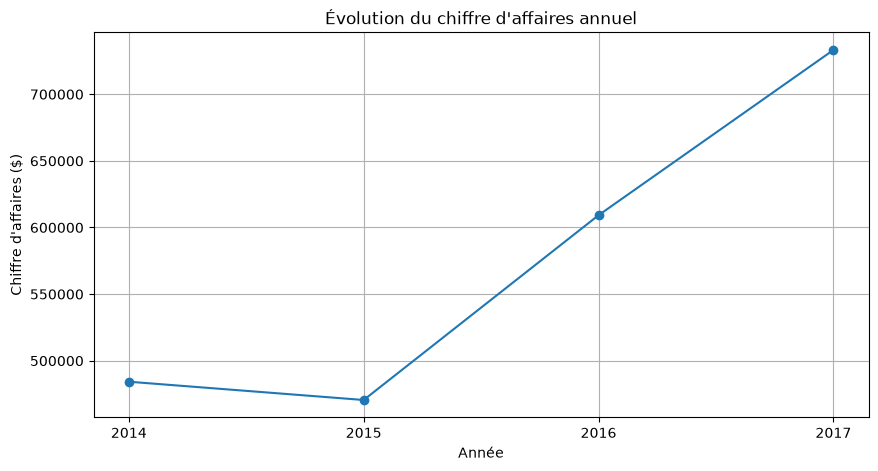

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\evolution_chiffre_affaires_annuel.png


In [90]:
from pathlib import Path
import matplotlib.pyplot as plt

# Créer le dossier reports s'il n'existe pas
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

# Construire le graphique
plt.figure(figsize=(10, 5))

plt.plot(
    ventes_annuelles["Année"],
    ventes_annuelles["Chiffre d'affaires"],
    marker="o"
)

plt.title("Évolution du chiffre d'affaires annuel")
plt.xlabel("Année")
plt.ylabel("Chiffre d'affaires ($)")
plt.xticks(ventes_annuelles["Année"])
plt.grid(True)

# Enregistrer le graphique
chemin_graphique = dossier_rapports / "evolution_chiffre_affaires_annuel.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [91]:
ventes_mensuelles = (
    df_nettoyage
    .set_index("Order Date")
    .resample("MS")["Sales"]
    .sum()
    .reset_index()
)

ventes_mensuelles.columns = ["Mois", "Chiffre d'affaires"]

display(ventes_mensuelles.head(12))

,Mois,Chiffre d'affaires
0,2014-01-01,14236.8950
1,2014-02-01,4519.8920
2,2014-03-01,55691.0090
3,2014-04-01,28295.3450
4,2014-05-01,23648.2870
5,2014-06-01,34595.1276
6,2014-07-01,33946.3930
7,2014-08-01,27909.4685
8,2014-09-01,81777.3508
9,2014-10-01,31453.3930


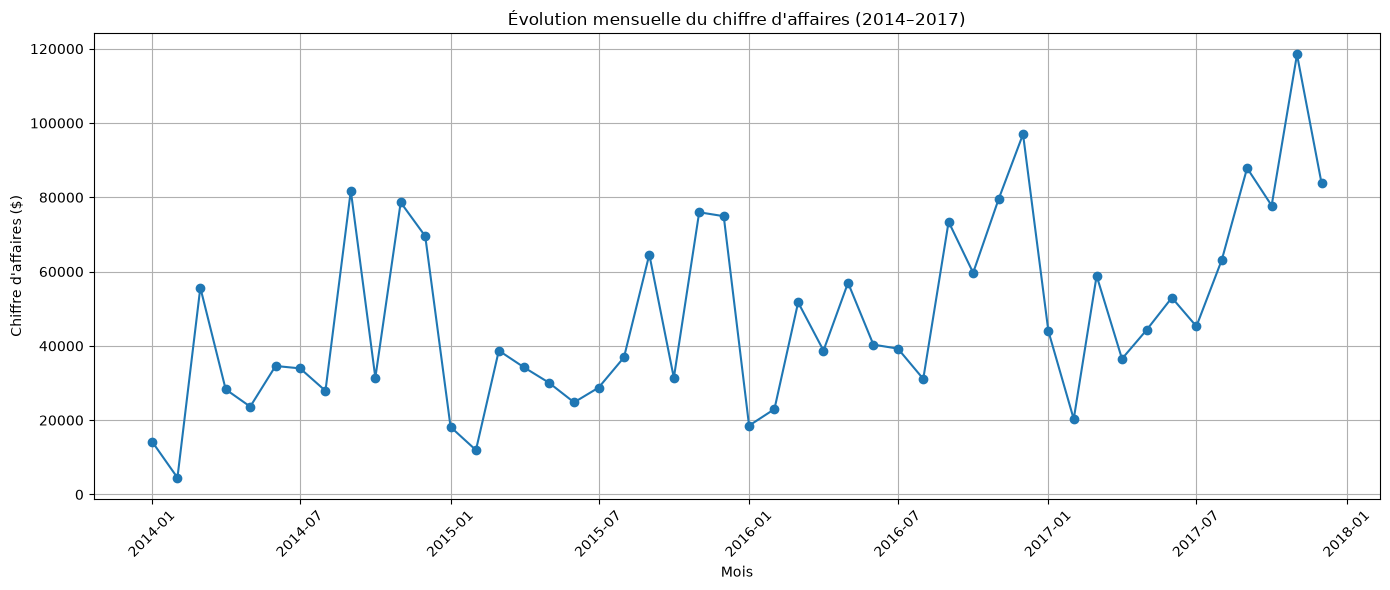

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\evolution_chiffre_affaires_mensuel.png


In [92]:
import matplotlib.pyplot as plt
from pathlib import Path

# Créer le graphique
plt.figure(figsize=(14, 6))

plt.plot(
    ventes_mensuelles["Mois"],
    ventes_mensuelles["Chiffre d'affaires"],
    marker="o",
    linewidth=1.5
)

plt.title("Évolution mensuelle du chiffre d'affaires (2014–2017)")
plt.xlabel("Mois")
plt.ylabel("Chiffre d'affaires ($)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

# Enregistrer le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "evolution_chiffre_affaires_mensuel.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [93]:
print("TOP 5 — Meilleurs mois")
display(
    ventes_mensuelles
    .sort_values("Chiffre d'affaires", ascending=False)
    .head(5)
)

print("TOP 5 — Mois les moins performants")
display(
    ventes_mensuelles
    .sort_values("Chiffre d'affaires", ascending=True)
    .head(5)
)

TOP 5 — Meilleurs mois


,Mois,Chiffre d'affaires
46,2017-11-01,118447.8250
35,2016-12-01,96999.0430
44,2017-09-01,87866.6520
47,2017-12-01,83829.3188
8,2014-09-01,81777.3508


TOP 5 — Mois les moins performants


,Mois,Chiffre d'affaires
1,2014-02-01,4519.8920
13,2015-02-01,11951.4110
0,2014-01-01,14236.8950
12,2015-01-01,18174.0756
24,2016-01-01,18542.4910


In [94]:
ventes_par_region = (
    df_nettoyage
    .groupby("Region")["Sales"]
    .sum()
    .reset_index()
    .sort_values("Sales", ascending=False)
)

ventes_par_region["Part du CA (%)"] = (
    ventes_par_region["Sales"] / df_nettoyage["Sales"].sum() * 100
)

ventes_par_region = ventes_par_region.rename(
    columns={"Sales": "Chiffre d'affaires"}
)

display(ventes_par_region)

,Region,Chiffre d'affaires,Part du CA (%)
3,West,725457.8245,31.580078
1,East,678781.2400,29.548188
0,Central,501239.8908,21.819594
2,South,391721.9050,17.052140


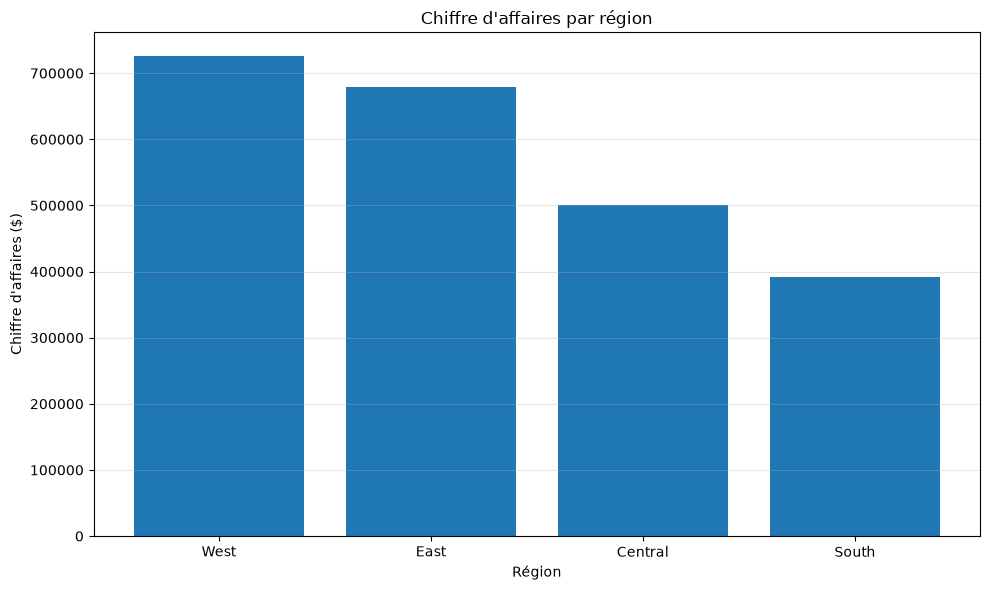

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\chiffre_affaires_par_region.png


In [95]:
import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(10, 6))

plt.bar(
    ventes_par_region["Region"],
    ventes_par_region["Chiffre d'affaires"]
)

plt.title("Chiffre d'affaires par région")
plt.xlabel("Région")
plt.ylabel("Chiffre d'affaires ($)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "chiffre_affaires_par_region.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [96]:
profit_par_region = (
    df_nettoyage
    .groupby("Region")["Profit"]
    .sum()
    .reset_index()
    .sort_values("Profit", ascending=False)
)

profit_par_region = profit_par_region.rename(
    columns={"Profit": "Profit total"}
)

profit_par_region["Marge bénéficiaire (%)"] = (
    profit_par_region["Profit total"]
    / df_nettoyage.groupby("Region")["Sales"].sum().reindex(
        profit_par_region["Region"]
    ).values
) * 100

display(profit_par_region)

,Region,Profit total,Marge bénéficiaire (%)
3,West,108418.4489,14.944831
1,East,91522.7800,13.483399
2,South,46749.4303,11.934342
0,Central,39706.3625,7.921629


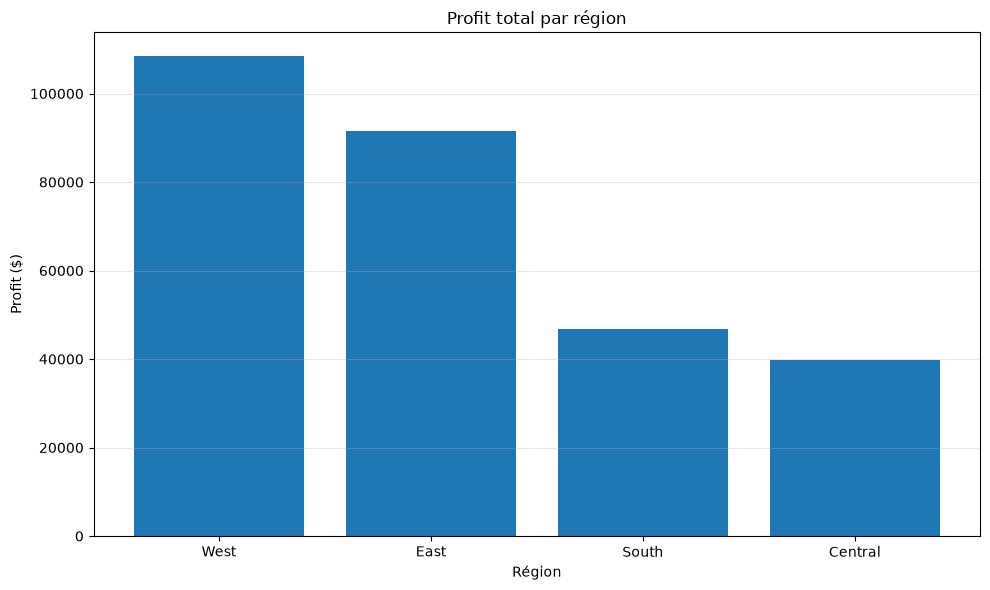

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\profit_par_region.png


In [97]:
import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(10, 6))

plt.bar(
    profit_par_region["Region"],
    profit_par_region["Profit total"]
)

plt.title("Profit total par région")
plt.xlabel("Région")
plt.ylabel("Profit ($)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "profit_par_region.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [98]:
ventes_par_categorie = (
    df_nettoyage
    .groupby("Category")["Sales"]
    .sum()
    .reset_index()
    .sort_values("Sales", ascending=False)
)

ventes_par_categorie["Part du CA (%)"] = (
    ventes_par_categorie["Sales"]
    / df_nettoyage["Sales"].sum()
    * 100
)

ventes_par_categorie = ventes_par_categorie.rename(
    columns={"Sales": "Chiffre d'affaires"}
)

display(ventes_par_categorie)

,Category,Chiffre d'affaires,Part du CA (%)
2,Technology,836154.0330,36.398821
0,Furniture,741999.7953,32.300171
1,Office Supplies,719047.0320,31.301008


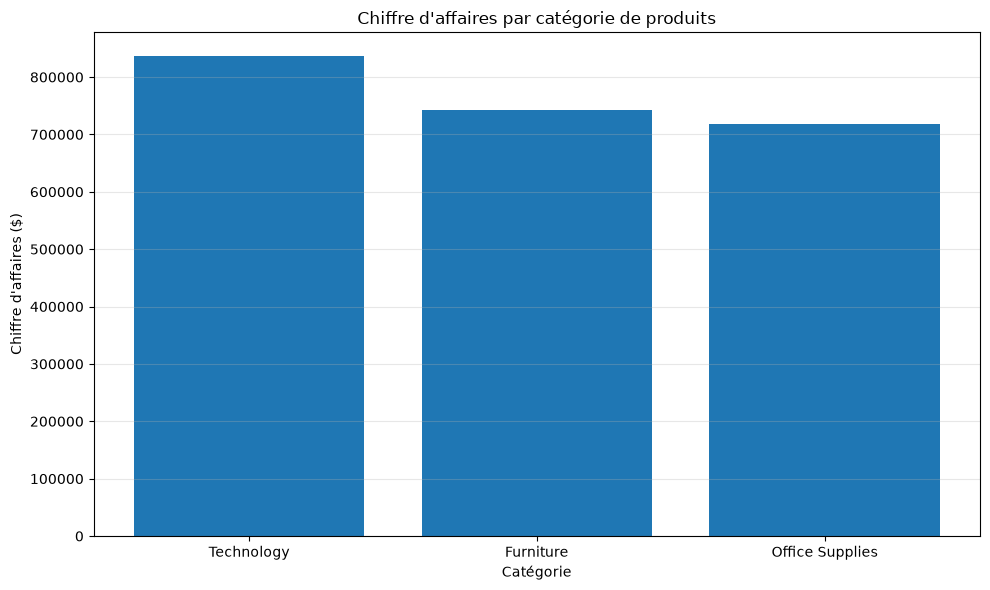

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\chiffre_affaires_par_categorie.png


In [99]:
import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(10, 6))

plt.bar(
    ventes_par_categorie["Category"],
    ventes_par_categorie["Chiffre d'affaires"]
)

plt.title("Chiffre d'affaires par catégorie de produits")
plt.xlabel("Catégorie")
plt.ylabel("Chiffre d'affaires ($)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "chiffre_affaires_par_categorie.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [100]:
profit_par_categorie = (
    df_nettoyage
    .groupby("Category")
    .agg(
        Profit_total=("Profit", "sum"),
        Chiffre_affaires=("Sales", "sum")
    )
    .reset_index()
    .sort_values("Profit_total", ascending=False)
)

profit_par_categorie["Marge bénéficiaire (%)"] = (
    profit_par_categorie["Profit_total"]
    / profit_par_categorie["Chiffre_affaires"]
    * 100
)

display(profit_par_categorie)

,Category,Profit_total,Chiffre_affaires,Marge bénéficiaire (%)
2,Technology,145454.9481,836154.0330,17.395712
1,Office Supplies,122490.8008,719047.0320,17.035158
0,Furniture,18451.2728,741999.7953,2.486695


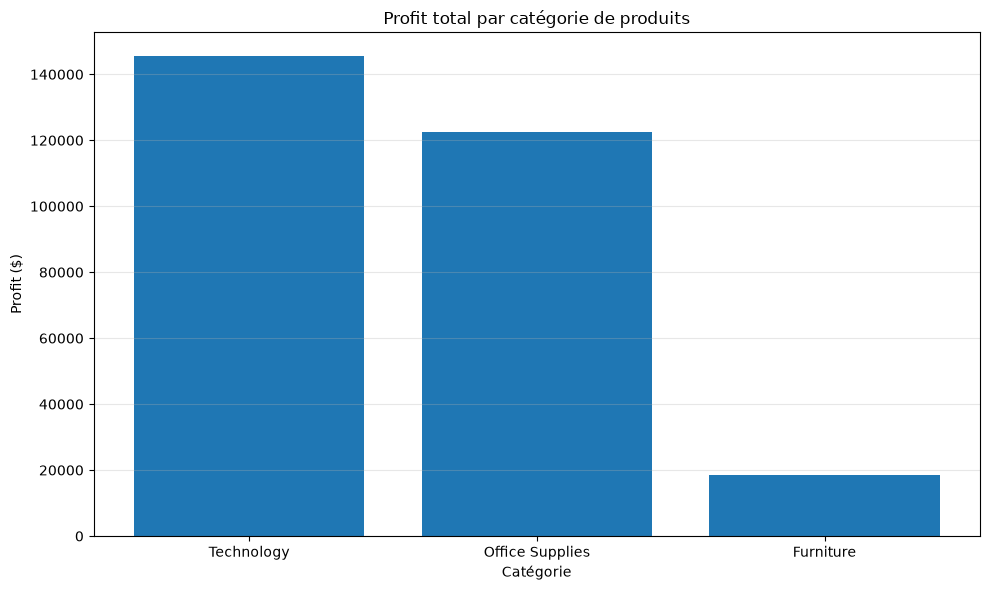

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\profit_par_categorie.png


In [101]:
import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(10, 6))

plt.bar(
    profit_par_categorie["Category"],
    profit_par_categorie["Profit_total"]
)

plt.title("Profit total par catégorie de produits")
plt.xlabel("Catégorie")
plt.ylabel("Profit ($)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "profit_par_categorie.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [102]:
ventes_par_sous_categorie = (
    df_nettoyage
    .groupby("Sub-Category")["Sales"]
    .sum()
    .reset_index()
    .sort_values("Sales", ascending=False)
)

ventes_par_sous_categorie = ventes_par_sous_categorie.rename(
    columns={"Sales": "Chiffre d'affaires"}
)

display(ventes_par_sous_categorie)

,Sub-Category,Chiffre d'affaires
13,Phones,330007.0540
5,Chairs,328449.1030
14,Storage,223843.6080
16,Tables,206965.5320
3,Binders,203412.7330
11,Machines,189238.6310
0,Accessories,167380.3180
6,Copiers,149528.0300
4,Bookcases,114879.9963
1,Appliances,107532.1610


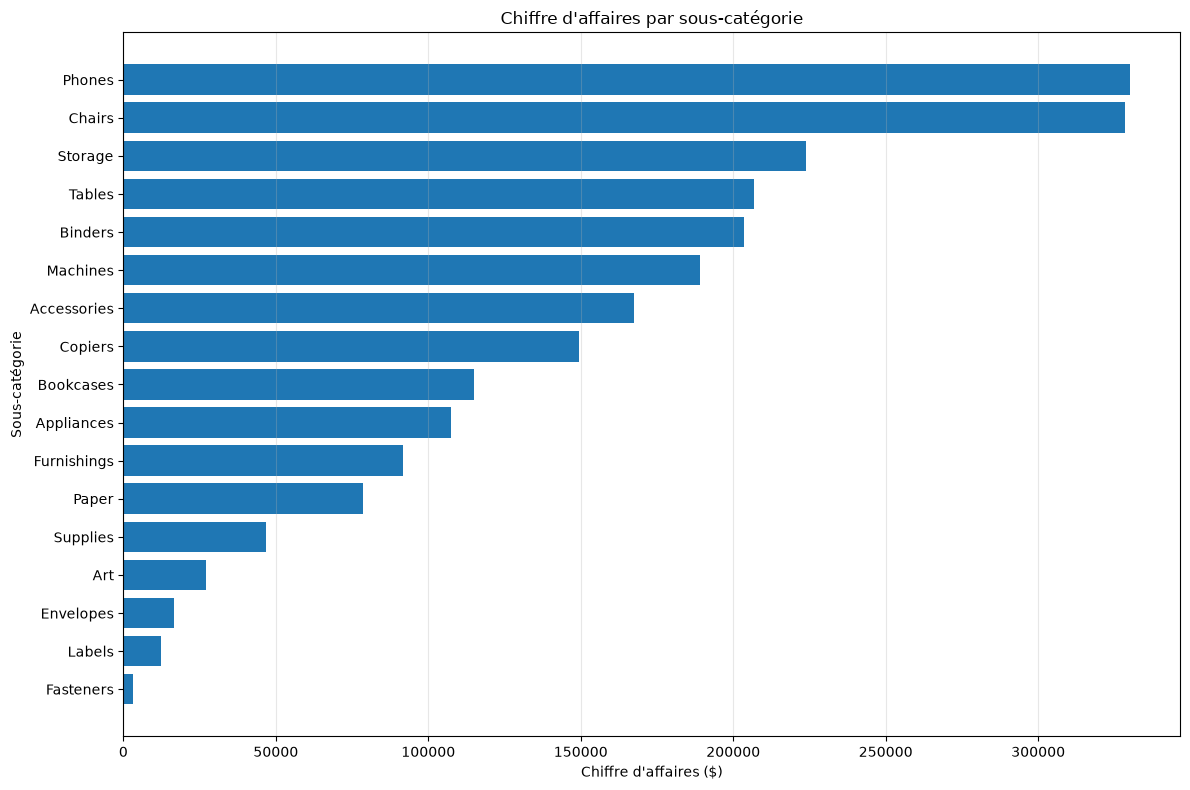

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\chiffre_affaires_par_sous_categorie.png


In [103]:
import matplotlib.pyplot as plt
from pathlib import Path

# Trier les sous-catégories pour faciliter la lecture
donnees_graphique = ventes_par_sous_categorie.sort_values(
    "Chiffre d'affaires",
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    donnees_graphique["Sub-Category"],
    donnees_graphique["Chiffre d'affaires"]
)

plt.title("Chiffre d'affaires par sous-catégorie")
plt.xlabel("Chiffre d'affaires ($)")
plt.ylabel("Sous-catégorie")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "chiffre_affaires_par_sous_categorie.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [104]:
profit_par_sous_categorie = (
    df_nettoyage
    .groupby("Sub-Category")
    .agg(
        Profit_total=("Profit", "sum"),
        Chiffre_affaires=("Sales", "sum")
    )
    .reset_index()
)

profit_par_sous_categorie["Marge bénéficiaire (%)"] = (
    profit_par_sous_categorie["Profit_total"]
    / profit_par_sous_categorie["Chiffre_affaires"]
    * 100
)

profit_par_sous_categorie = profit_par_sous_categorie.sort_values(
    "Profit_total",
    ascending=False
)

display(profit_par_sous_categorie)

,Sub-Category,Profit_total,Chiffre_affaires,Marge bénéficiaire (%)
6,Copiers,55617.8249,149528.0300,37.195585
13,Phones,44515.7306,330007.0540,13.489327
0,Accessories,41936.6357,167380.3180,25.054700
12,Paper,34053.5693,78479.2060,43.391837
3,Binders,30221.7633,203412.7330,14.857361
5,Chairs,26590.1663,328449.1030,8.095673
14,Storage,21278.8264,223843.6080,9.506113
1,Appliances,18138.0054,107532.1610,16.867517
9,Furnishings,13059.1436,91705.1640,14.240358
7,Envelopes,6964.1767,16476.4020,42.267582


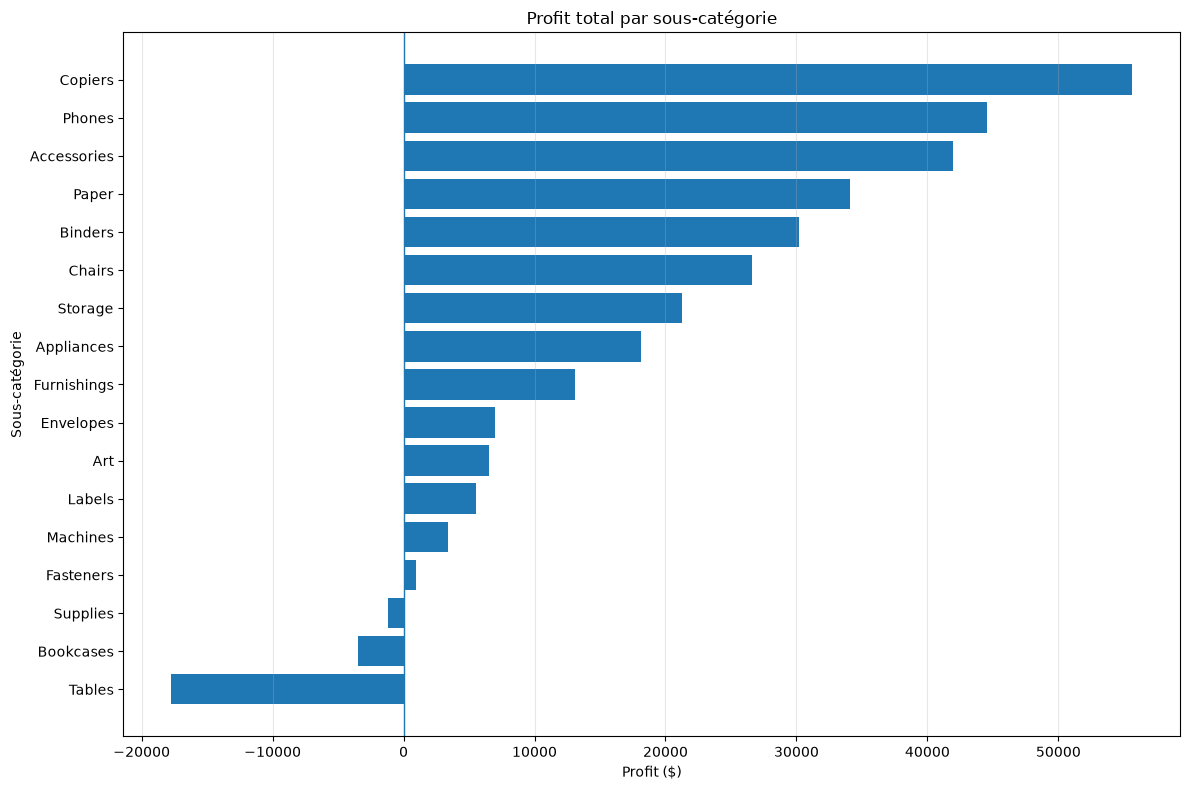

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\profit_par_sous_categorie.png


In [105]:
import matplotlib.pyplot as plt
from pathlib import Path

# Trier les sous-catégories par profit
donnees_graphique = profit_par_sous_categorie.sort_values(
    "Profit_total",
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    donnees_graphique["Sub-Category"],
    donnees_graphique["Profit_total"]
)

# Ligne de référence : profit nul
plt.axvline(x=0, linewidth=1)

plt.title("Profit total par sous-catégorie")
plt.xlabel("Profit ($)")
plt.ylabel("Sous-catégorie")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "profit_par_sous_categorie.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [106]:
performance_par_segment = (
    df_nettoyage
    .groupby("Segment")
    .agg(
        Chiffre_affaires=("Sales", "sum"),
        Profit_total=("Profit", "sum"),
        Nombre_commandes=("Order ID", "nunique")
    )
    .reset_index()
)

performance_par_segment["Marge bénéficiaire (%)"] = (
    performance_par_segment["Profit_total"]
    / performance_par_segment["Chiffre_affaires"]
    * 100
)

performance_par_segment = performance_par_segment.sort_values(
    "Chiffre_affaires",
    ascending=False
)

display(performance_par_segment)

,Segment,Chiffre_affaires,Profit_total,Nombre_commandes,Marge bénéficiaire (%)
0,Consumer,1.161401e+06,134119.2092,2586,11.548050
1,Corporate,7.061464e+05,91979.1340,1514,13.025506
2,Home Office,4.296531e+05,60298.6785,909,14.034269


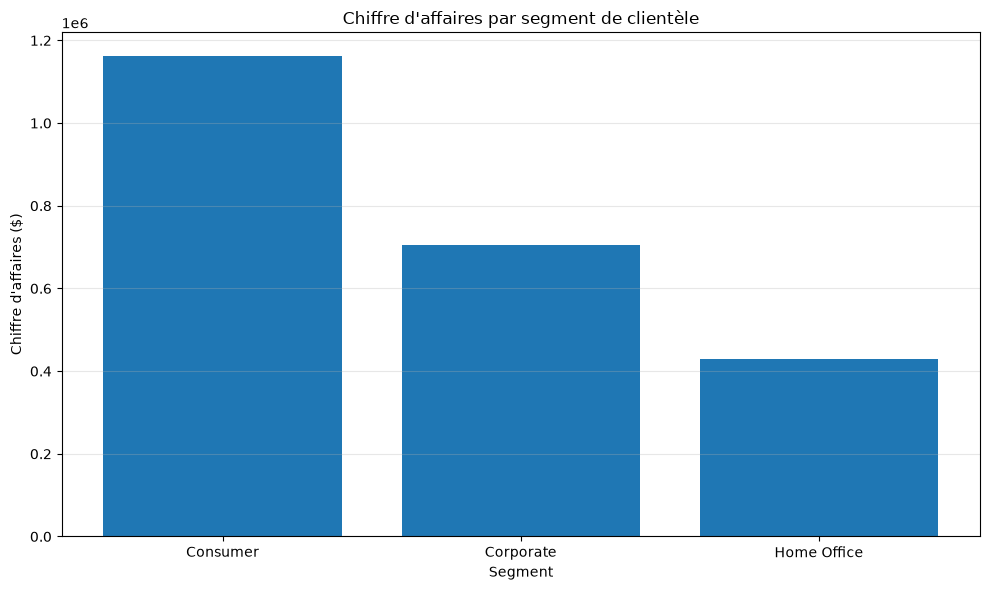

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\chiffre_affaires_par_segment.png


In [107]:
import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(10, 6))

plt.bar(
    performance_par_segment["Segment"],
    performance_par_segment["Chiffre_affaires"]
)

plt.title("Chiffre d'affaires par segment de clientèle")
plt.xlabel("Segment")
plt.ylabel("Chiffre d'affaires ($)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "chiffre_affaires_par_segment.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

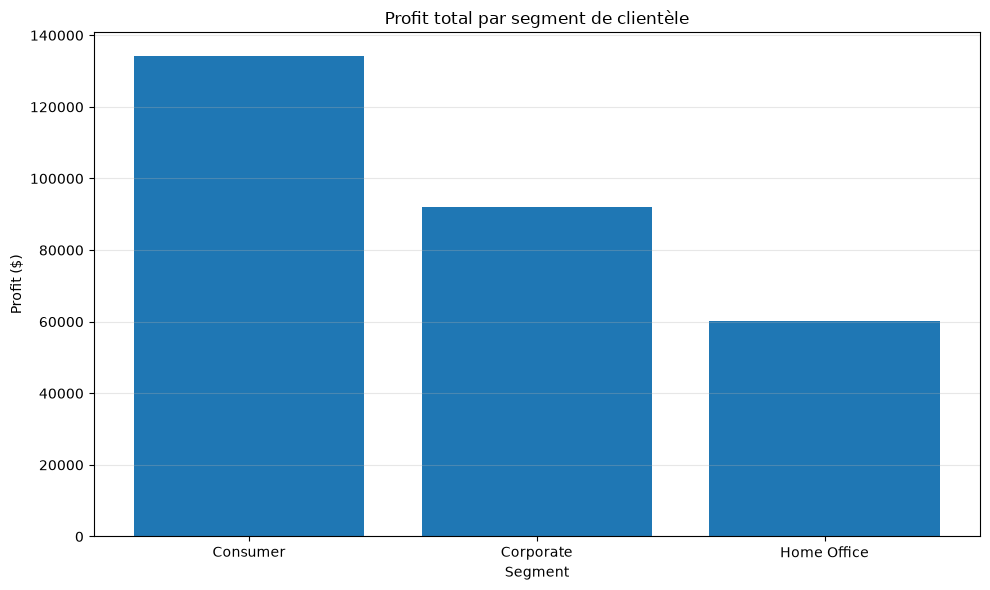

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\profit_par_segment.png


In [108]:
import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(10, 6))

plt.bar(
    performance_par_segment["Segment"],
    performance_par_segment["Profit_total"]
)

plt.title("Profit total par segment de clientèle")
plt.xlabel("Segment")
plt.ylabel("Profit ($)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "profit_par_segment.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [109]:
performance_par_expedition = (
    df_nettoyage
    .groupby("Ship Mode")
    .agg(
        Nombre_commandes=("Order ID", "nunique"),
        Chiffre_affaires=("Sales", "sum"),
        Profit_total=("Profit", "sum")
    )
    .reset_index()
)

performance_par_expedition["Marge bénéficiaire (%)"] = (
    performance_par_expedition["Profit_total"]
    / performance_par_expedition["Chiffre_affaires"]
    * 100
)

performance_par_expedition = performance_par_expedition.sort_values(
    "Nombre_commandes",
    ascending=False
)

display(performance_par_expedition)

,Ship Mode,Nombre_commandes,Chiffre_affaires,Profit_total,Marge bénéficiaire (%)
3,Standard Class,2994,1.358216e+06,164088.7875,12.081202
2,Second Class,964,4.591936e+05,57446.6354,12.510331
0,First Class,787,3.514284e+05,48969.8399,13.934513
1,Same Day,264,1.283631e+05,15891.7589,12.380315


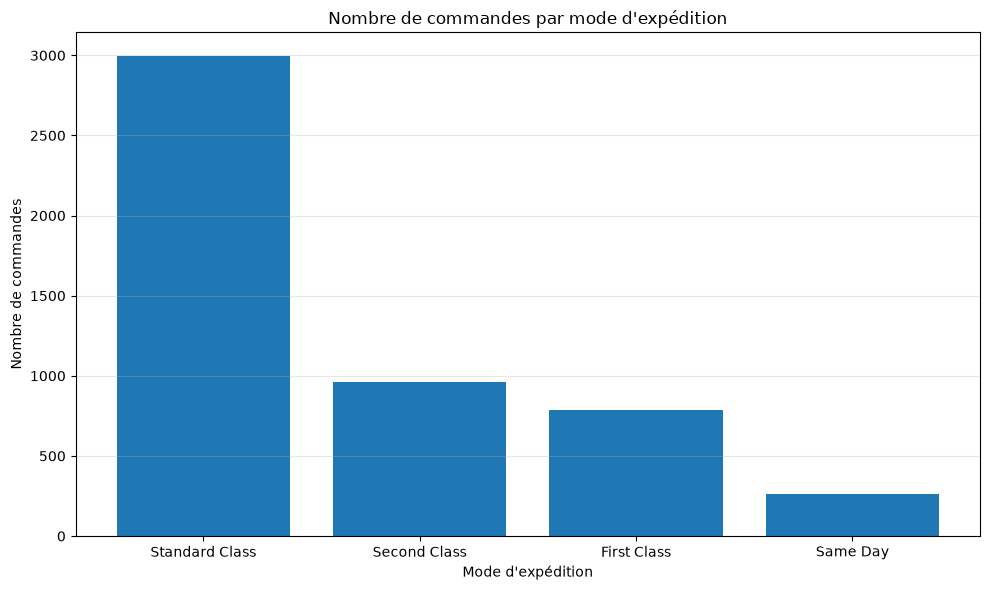

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\commandes_par_mode_expedition.png


In [110]:
import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(10, 6))

plt.bar(
    performance_par_expedition["Ship Mode"],
    performance_par_expedition["Nombre_commandes"]
)

plt.title("Nombre de commandes par mode d'expédition")
plt.xlabel("Mode d'expédition")
plt.ylabel("Nombre de commandes")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "commandes_par_mode_expedition.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [111]:
performance_annuelle = (
    df_nettoyage
    .groupby(df_nettoyage["Order Date"].dt.year)
    .agg(
        Chiffre_affaires=("Sales", "sum"),
        Profit_total=("Profit", "sum")
    )
    .reset_index()
)

performance_annuelle = performance_annuelle.rename(
    columns={"Order Date": "Année"}
)

performance_annuelle["Marge bénéficiaire (%)"] = (
    performance_annuelle["Profit_total"]
    / performance_annuelle["Chiffre_affaires"]
    * 100
)

display(performance_annuelle)

,Année,Chiffre_affaires,Profit_total,Marge bénéficiaire (%)
0,2014,484247.4981,49543.9741,10.231126
1,2015,470532.5090,61618.6037,13.095504
2,2016,609205.5980,81795.1743,13.426530
3,2017,733215.2552,93439.2696,12.743771


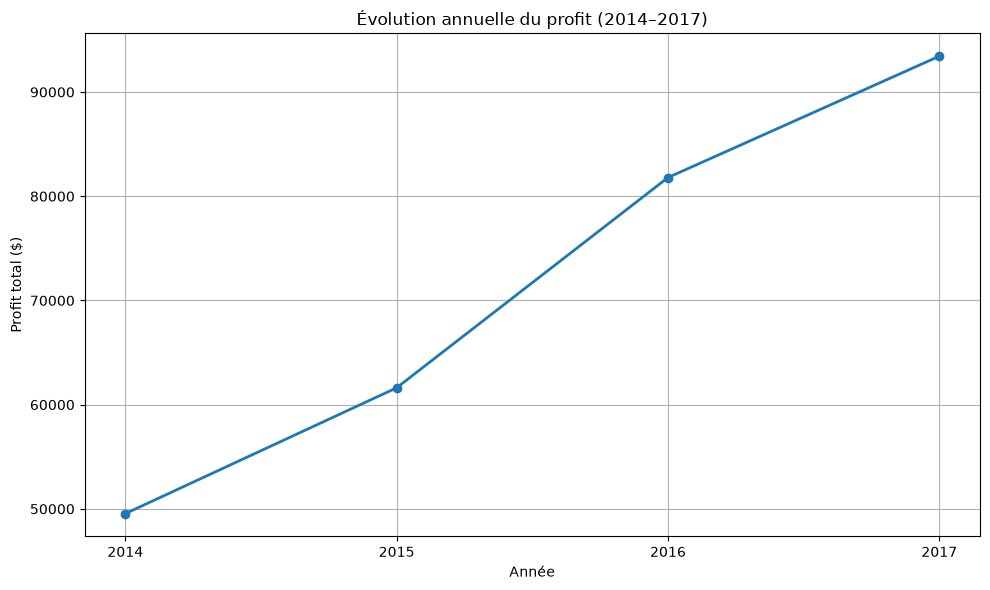

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\evolution_profit_annuel.png


In [112]:
import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(10, 6))

plt.plot(
    performance_annuelle["Année"],
    performance_annuelle["Profit_total"],
    marker="o",
    linewidth=2
)

plt.title("Évolution annuelle du profit (2014–2017)")
plt.xlabel("Année")
plt.ylabel("Profit total ($)")
plt.xticks(performance_annuelle["Année"])
plt.grid(True)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "evolution_profit_annuel.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

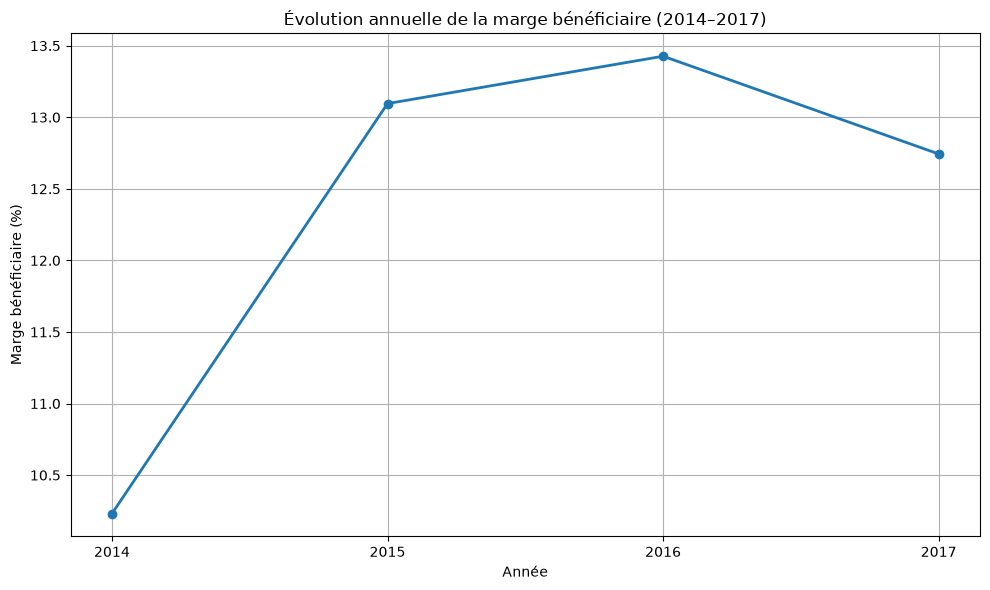

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\evolution_marge_annuelle.png


In [113]:
import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(10, 6))

plt.plot(
    performance_annuelle["Année"],
    performance_annuelle["Marge bénéficiaire (%)"],
    marker="o",
    linewidth=2
)

plt.title("Évolution annuelle de la marge bénéficiaire (2014–2017)")
plt.xlabel("Année")
plt.ylabel("Marge bénéficiaire (%)")
plt.xticks(performance_annuelle["Année"])
plt.grid(True)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "evolution_marge_annuelle.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [114]:
performance_par_remise = (
    df_nettoyage
    .groupby("Discount")
    .agg(
        Nombre_lignes=("Discount", "size"),
        Chiffre_affaires=("Sales", "sum"),
        Profit_total=("Profit", "sum")
    )
    .reset_index()
    .sort_values("Discount")
)

performance_par_remise["Marge bénéficiaire (%)"] = (
    performance_par_remise["Profit_total"]
    / performance_par_remise["Chiffre_affaires"]
    * 100
)

performance_par_remise["Taux de remise (%)"] = (
    performance_par_remise["Discount"] * 100
)

display(performance_par_remise)

,Discount,Nombre_lignes,Chiffre_affaires,Profit_total,Marge bénéficiaire (%),Taux de remise (%)
0,0.00,4798,1.087908e+06,320987.6032,29.505019,0.0
1,0.10,94,5.436935e+04,9029.1770,16.607108,10.0
2,0.15,52,2.755852e+04,1418.9915,5.149012,15.0
3,0.20,3657,7.645944e+05,90337.3060,11.815063,20.0
4,0.30,227,1.032267e+05,-10369.2774,-10.045155,30.0
5,0.32,27,1.449346e+04,-2391.1377,-16.498047,32.0
6,0.40,206,1.164178e+05,-23057.0504,-19.805437,40.0
7,0.45,11,5.484974e+03,-2493.1111,-45.453472,45.0
8,0.50,66,5.891854e+04,-20506.4281,-34.804712,50.0
9,0.60,138,6.644700e+03,-5944.6552,-89.464614,60.0


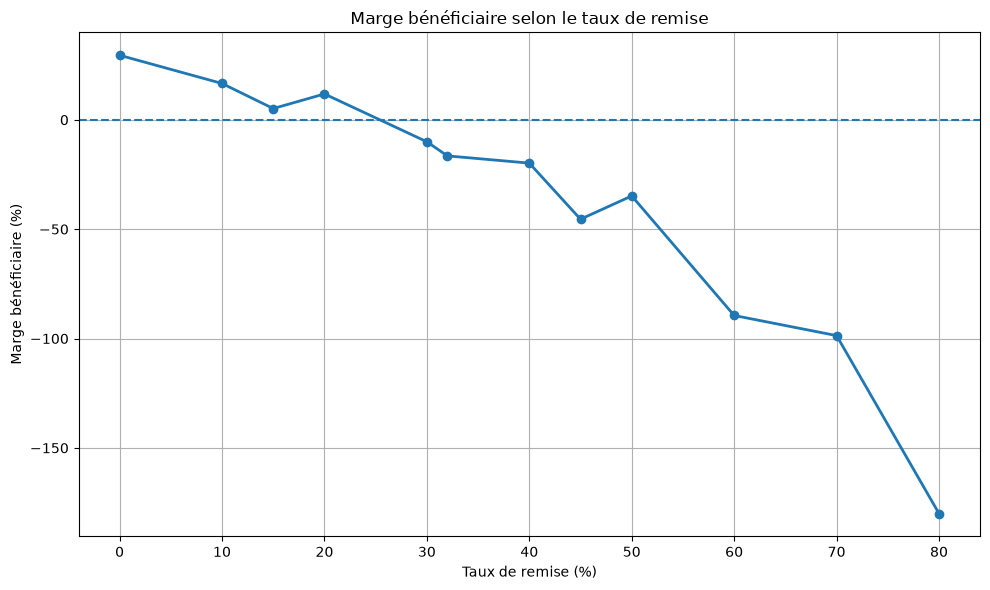

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\marge_beneficiaire_par_remise.png


In [115]:
import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(10, 6))

plt.plot(
    performance_par_remise["Taux de remise (%)"],
    performance_par_remise["Marge bénéficiaire (%)"],
    marker="o",
    linewidth=2
)

plt.axhline(y=0, linestyle="--")

plt.title("Marge bénéficiaire selon le taux de remise")
plt.xlabel("Taux de remise (%)")
plt.ylabel("Marge bénéficiaire (%)")
plt.grid(True)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "marge_beneficiaire_par_remise.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [116]:
performance_clients = (
    df_nettoyage
    .groupby(["Customer ID", "Customer Name"])
    .agg(
        Chiffre_affaires=("Sales", "sum"),
        Profit_total=("Profit", "sum"),
        Nombre_commandes=("Order ID", "nunique"),
        Quantite_totale=("Quantity", "sum")
    )
    .reset_index()
)

performance_clients["Marge bénéficiaire (%)"] = (
    performance_clients["Profit_total"]
    / performance_clients["Chiffre_affaires"]
    * 100
)

top_10_clients = (
    performance_clients
    .sort_values("Chiffre_affaires", ascending=False)
    .head(10)
)

display(top_10_clients)

,Customer ID,Customer Name,Chiffre_affaires,Profit_total,Nombre_commandes,Quantite_totale,Marge bénéficiaire (%)
700,SM-20320,Sean Miller,25043.050,-1980.7393,5,50,-7.909337
741,TC-20980,Tamara Chand,19052.218,8981.3239,5,42,47.140569
621,RB-19360,Raymond Buch,15117.339,6976.0959,6,71,46.146322
730,TA-21385,Tom Ashbrook,14595.620,4703.7883,4,36,32.227396
6,AB-10105,Adrian Barton,14473.571,5444.8055,10,73,37.618950
434,KL-16645,Ken Lonsdale,14175.229,806.8550,12,113,5.692007
669,SC-20095,Sanjit Chand,14142.334,5757.4119,9,87,40.710479
327,HL-15040,Hunter Lopez,12873.298,5622.4292,6,50,43.675127
683,SE-20110,Sanjit Engle,12209.438,2650.6769,11,78,21.710065
131,CC-12370,Christopher Conant,12129.072,2177.0493,5,34,17.949018


In [117]:
top_10_clients_profit = (
    performance_clients
    .sort_values("Profit_total", ascending=False)
    .head(10)
)

display(top_10_clients_profit)

,Customer ID,Customer Name,Chiffre_affaires,Profit_total,Nombre_commandes,Quantite_totale,Marge bénéficiaire (%)
741,TC-20980,Tamara Chand,19052.218,8981.3239,5,42,47.140569
621,RB-19360,Raymond Buch,15117.339,6976.0959,6,71,46.146322
669,SC-20095,Sanjit Chand,14142.334,5757.4119,9,87,40.710479
327,HL-15040,Hunter Lopez,12873.298,5622.4292,6,50,43.675127
6,AB-10105,Adrian Barton,14473.571,5444.8055,10,73,37.618950
730,TA-21385,Tom Ashbrook,14595.620,4703.7883,4,36,32.227396
160,CM-12385,Christopher Martinez,8954.020,3899.8904,4,34,43.554631
424,KD-16495,Keith Dawkins,8181.256,3038.6254,12,84,37.141307
48,AR-10540,Andy Reiter,6608.448,2884.6208,6,33,43.650503
234,DR-12940,Daniel Raglin,8350.868,2869.0760,8,57,34.356620


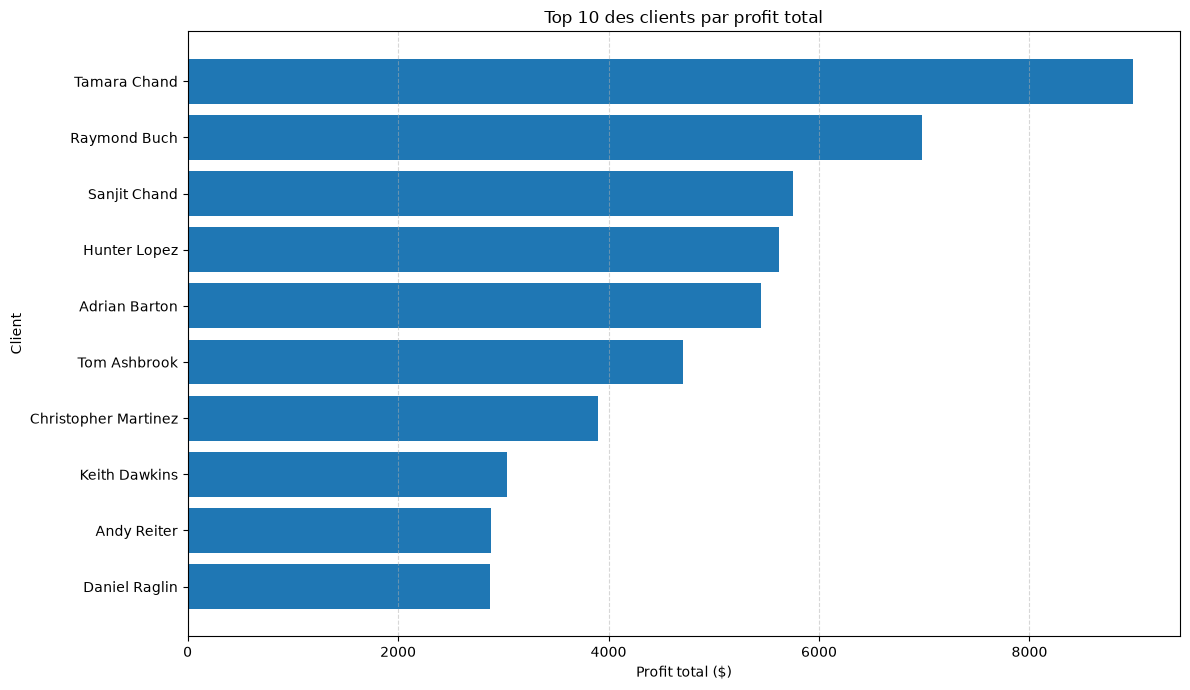

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\top_10_clients_profit.png


In [118]:
import matplotlib.pyplot as plt
from pathlib import Path

top_clients_graphique = top_10_clients_profit.sort_values(
    "Profit_total",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_clients_graphique["Customer Name"],
    top_clients_graphique["Profit_total"]
)

plt.title("Top 10 des clients par profit total")
plt.xlabel("Profit total ($)")
plt.ylabel("Client")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "top_10_clients_profit.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [119]:
clients_deficitaires = (
    performance_clients[
        performance_clients["Profit_total"] < 0
    ]
    .sort_values("Profit_total", ascending=True)
)

print("Nombre de clients déficitaires :", len(clients_deficitaires))

display(
    clients_deficitaires.head(10)
)

Nombre de clients déficitaires : 155


,Customer ID,Customer Name,Chiffre_affaires,Profit_total,Nombre_commandes,Quantite_totale,Marge bénéficiaire (%)
180,CS-12505,Cindy Stewart,5690.055,-6626.3895,6,40,-116.455632
310,GT-14635,Grant Thornton,9351.212,-4108.6589,3,26,-43.937181
459,LF-17185,Luke Foster,3930.509,-3583.9770,7,69,-91.183534
711,SR-20425,Sharelle Roach,3233.481,-3333.9144,5,34,-103.106046
322,HG-14965,Henry Goldwyn,3247.642,-2797.9635,12,68,-86.153692
555,NC-18415,Nathan Cano,2218.990,-2204.8072,6,38,-99.360844
666,SB-20290,Sean Braxton,8057.891,-2082.7451,7,84,-25.847273
700,SM-20320,Sean Miller,25043.050,-1980.7393,5,50,-7.909337
165,CP-12340,Christine Phan,5888.275,-1850.3029,8,59,-31.423514
560,NF-18385,Natalie Fritzler,8322.826,-1695.9714,7,52,-20.377350


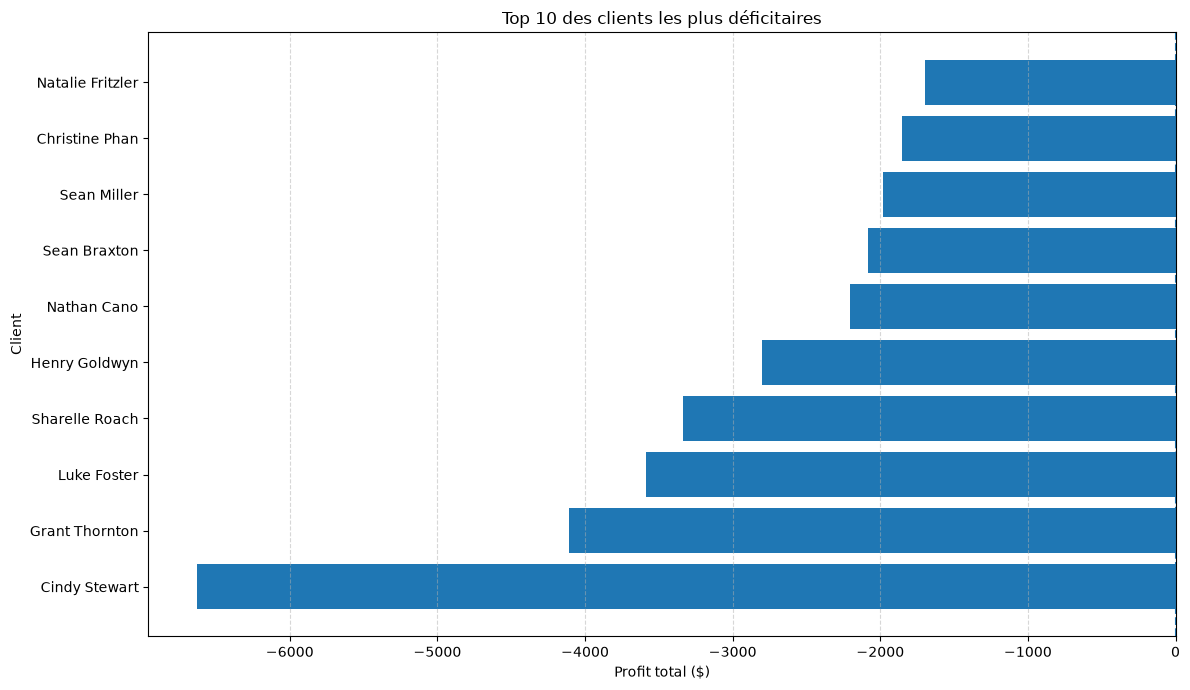

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\top_10_clients_deficitaires.png


In [120]:
import matplotlib.pyplot as plt
from pathlib import Path

top_10_clients_deficitaires = clients_deficitaires.head(10)

top_clients_deficit_graphique = top_10_clients_deficitaires.sort_values(
    "Profit_total",
    ascending=True
)

plt.figure(figsize=(12, 7))

plt.barh(
    top_clients_deficit_graphique["Customer Name"],
    top_clients_deficit_graphique["Profit_total"]
)

plt.axvline(x=0, linestyle="--")

plt.title("Top 10 des clients les plus déficitaires")
plt.xlabel("Profit total ($)")
plt.ylabel("Client")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "top_10_clients_deficitaires.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [121]:
performance_produits = (
    df_nettoyage
    .groupby(
        ["Product ID", "Product Name", "Category", "Sub-Category"]
    )
    .agg(
        Chiffre_affaires=("Sales", "sum"),
        Profit_total=("Profit", "sum"),
        Quantite_totale=("Quantity", "sum"),
        Nombre_commandes=("Order ID", "nunique")
    )
    .reset_index()
)

performance_produits["Marge bénéficiaire (%)"] = (
    performance_produits["Profit_total"]
    / performance_produits["Chiffre_affaires"]
    * 100
)

top_10_produits = (
    performance_produits
    .sort_values("Chiffre_affaires", ascending=False)
    .head(10)
)

display(top_10_produits)

,Product ID,Product Name,Category,Sub-Category,Chiffre_affaires,Profit_total,Quantite_totale,Nombre_commandes,Marge bénéficiaire (%)
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,61599.824,2.519993e+04,20,5,4.090909e+01
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,Binders,27453.384,7.753039e+03,31,10,2.824074e+01
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,Technology,Machines,22638.480,-1.811078e+03,6,1,-8.000000e+00
82,FUR-CH-10002024,HON 5400 Series Task Chairs for Big and Tall,Furniture,Chairs,21870.576,5.684342e-14,39,8,2.599082e-16
701,OFF-BI-10001359,GBC DocuBind TL300 Electric Binding System,Office Supplies,Binders,19823.479,2.233505e+03,37,11,1.126697e+01
667,OFF-BI-10000545,GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,Binders,19024.500,7.609800e+02,48,9,4.000000e+00
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,Technology,Copiers,18839.686,6.983884e+03,38,8,3.707006e+01
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,Technology,Machines,18374.895,4.094977e+03,12,3,2.228571e+01
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,17965.068,-1.878166e+03,27,6,-1.045455e+01
1443,OFF-SU-10000151,High Speed Automatic Electric Letter Opener,Office Supplies,Supplies,17030.312,-2.620048e+02,11,3,-1.538462e+00


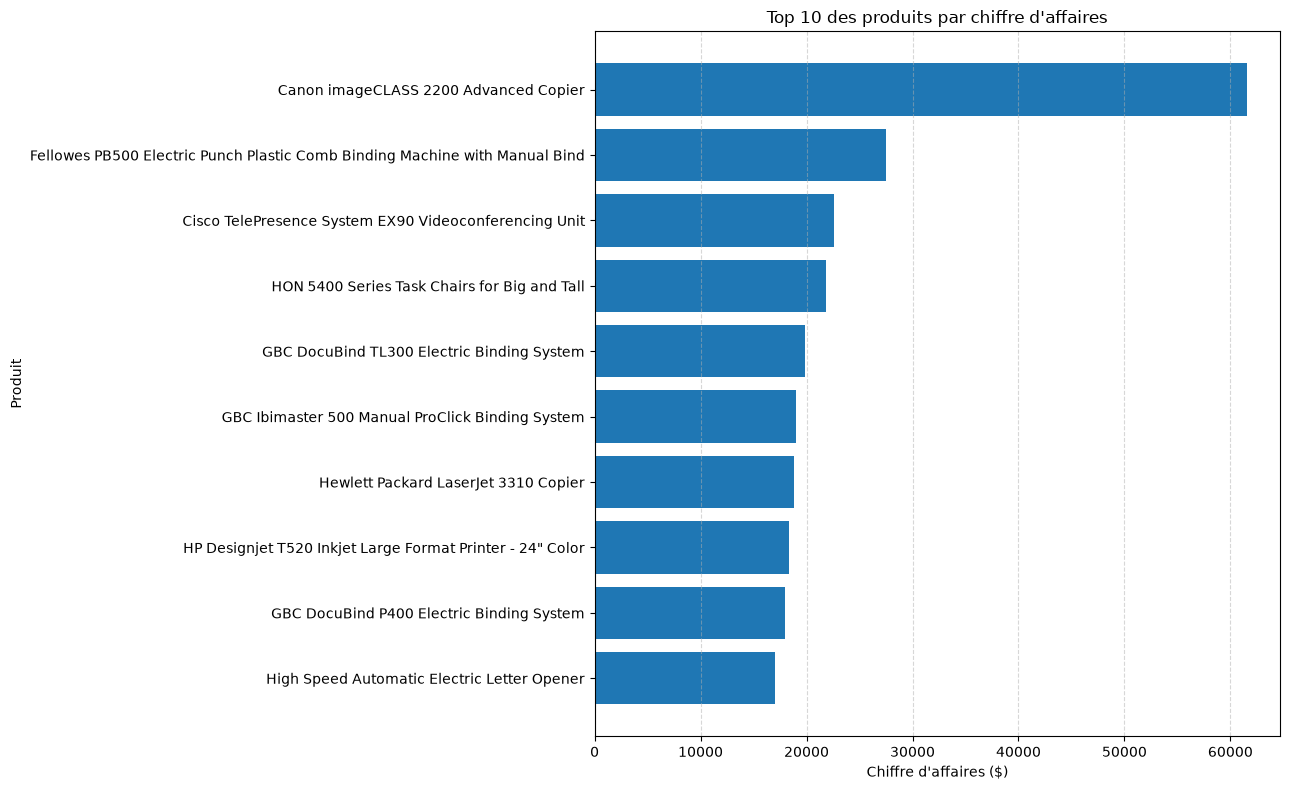

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\top_10_produits_chiffre_affaires.png


In [122]:
import matplotlib.pyplot as plt
from pathlib import Path

top_produits_graphique = top_10_produits.sort_values(
    "Chiffre_affaires",
    ascending=True
)

plt.figure(figsize=(13, 8))

plt.barh(
    top_produits_graphique["Product Name"],
    top_produits_graphique["Chiffre_affaires"]
)

plt.title("Top 10 des produits par chiffre d'affaires")
plt.xlabel("Chiffre d'affaires ($)")
plt.ylabel("Produit")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "top_10_produits_chiffre_affaires.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [123]:
top_10_produits_profit = (
    performance_produits
    .sort_values("Profit_total", ascending=False)
    .head(10)
)

display(top_10_produits_profit)

,Product ID,Product Name,Category,Sub-Category,Chiffre_affaires,Profit_total,Quantite_totale,Nombre_commandes,Marge bénéficiaire (%)
1640,TEC-CO-10004722,Canon imageCLASS 2200 Advanced Copier,Technology,Copiers,61599.824,25199.9280,20,5,40.909091
787,OFF-BI-10003527,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,Binders,27453.384,7753.0390,31,10,28.240741
1630,TEC-CO-10001449,Hewlett Packard LaserJet 3310 Copier,Technology,Copiers,18839.686,6983.8836,38,8,37.070064
1637,TEC-CO-10003763,Canon PC1060 Personal Laser Copier,Technology,Copiers,11619.834,4570.9347,19,4,39.337349
1657,TEC-MA-10001127,HP Designjet T520 Inkjet Large Format Printer ...,Technology,Machines,18374.895,4094.9766,12,3,22.285714
1693,TEC-MA-10003979,Ativa V4110MDD Micro-Cut Shredder,Technology,Machines,7699.890,3772.9461,11,2,49.000000
1656,TEC-MA-10001047,"3D Systems Cube Printer, 2nd Generation, Magenta",Technology,Machines,14299.890,3717.9714,11,2,26.000000
1541,TEC-AC-10002049,Plantronics Savi W720 Multi-Device Wireless He...,Technology,Accessories,9367.290,3696.2820,24,7,39.459459
692,OFF-BI-10001120,Ibico EPK-21 Electric Binding System,Office Supplies,Binders,15875.916,3345.2823,13,3,21.071429
1643,TEC-MA-10000045,Zebra ZM400 Thermal Label Printer,Technology,Machines,6965.700,3343.5360,6,2,48.000000


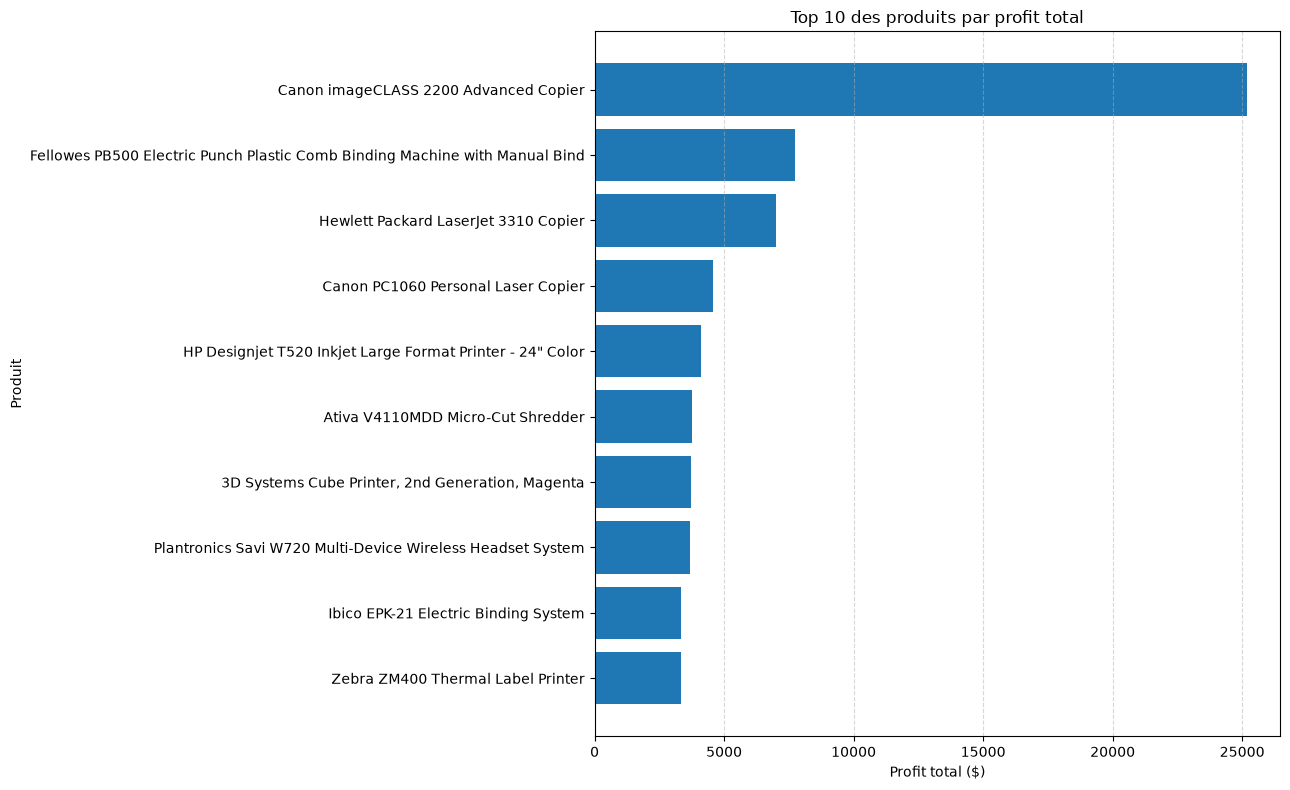

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\top_10_produits_profit.png


In [124]:
import matplotlib.pyplot as plt
from pathlib import Path

top_produits_profit_graphique = top_10_produits_profit.sort_values(
    "Profit_total",
    ascending=True
)

plt.figure(figsize=(13, 8))

plt.barh(
    top_produits_profit_graphique["Product Name"],
    top_produits_profit_graphique["Profit_total"]
)

plt.title("Top 10 des produits par profit total")
plt.xlabel("Profit total ($)")
plt.ylabel("Produit")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "top_10_produits_profit.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [125]:
produits_deficitaires = (
    performance_produits[
        performance_produits["Profit_total"] < 0
    ]
    .sort_values("Profit_total", ascending=True)
)

print("Nombre de produits déficitaires :", len(produits_deficitaires))

top_10_produits_deficitaires = produits_deficitaires.head(10)

display(top_10_produits_deficitaires)

Nombre de produits déficitaires : 306


,Product ID,Product Name,Category,Sub-Category,Chiffre_affaires,Profit_total,Quantite_totale,Nombre_commandes,Marge bénéficiaire (%)
1645,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,Technology,Machines,11099.963,-8879.9704,9,3,-80.000000
1650,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,Technology,Machines,16829.901,-4589.9730,18,4,-27.272727
1696,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,Technology,Machines,7999.980,-3839.9904,4,1,-48.000000
326,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,Tables,9917.640,-2876.1156,27,5,-29.000000
344,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,Furniture,Tables,9544.725,-1934.3976,33,7,-20.266667
858,OFF-BI-10004995,GBC DocuBind P400 Electric Binding System,Office Supplies,Binders,17965.068,-1878.1662,27,6,-10.454545
1669,TEC-MA-10002412,Cisco TelePresence System EX90 Videoconferenci...,Technology,Machines,22638.480,-1811.0784,6,1,-8.000000
1465,OFF-SU-10002881,Martin Yale Chadless Opener Electric Letter Op...,Office Supplies,Supplies,16656.200,-1299.1836,22,6,-7.800000
346,FUR-TA-10001950,Balt Solid Wood Round Tables,Furniture,Tables,6518.754,-1201.0581,19,4,-18.424658
375,FUR-TA-10004289,BoxOffice By Design Rectangular and Half-Moon ...,Furniture,Tables,1706.250,-1148.4375,15,3,-67.307692


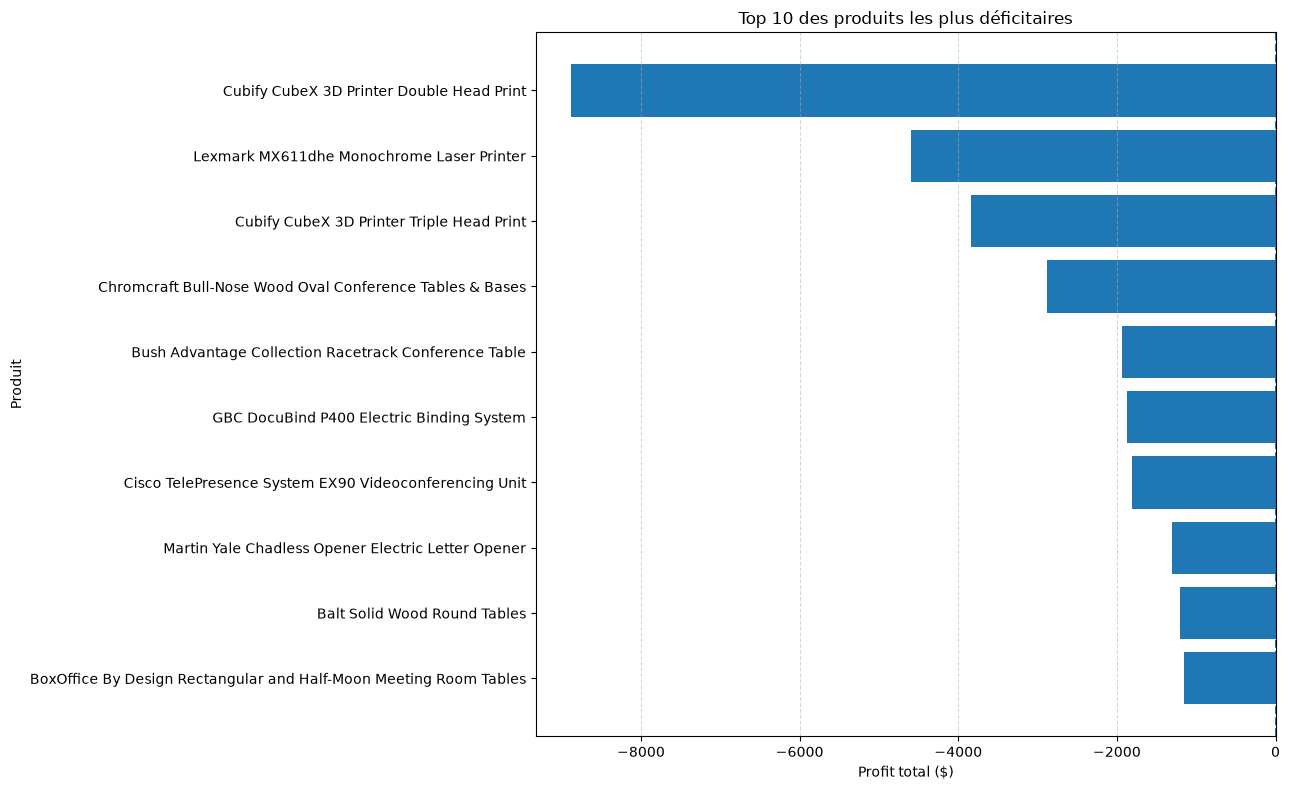

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\top_10_produits_deficitaires.png


In [126]:
import matplotlib.pyplot as plt
from pathlib import Path

top_produits_deficit_graphique = (
    top_10_produits_deficitaires
    .sort_values("Profit_total", ascending=False)
)

plt.figure(figsize=(13, 8))

plt.barh(
    top_produits_deficit_graphique["Product Name"],
    top_produits_deficit_graphique["Profit_total"]
)

plt.axvline(x=0, linestyle="--")

plt.title("Top 10 des produits les plus déficitaires")
plt.xlabel("Profit total ($)")
plt.ylabel("Produit")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "top_10_produits_deficitaires.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

In [127]:
performance_categories_produits = (
    performance_produits
    .groupby("Category")
    .agg(
        Nombre_produits=("Product ID", "nunique"),
        Chiffre_affaires=("Chiffre_affaires", "sum"),
        Profit_total=("Profit_total", "sum"),
        Quantite_totale=("Quantite_totale", "sum")
    )
    .reset_index()
)

performance_categories_produits["Marge bénéficiaire (%)"] = (
    performance_categories_produits["Profit_total"]
    / performance_categories_produits["Chiffre_affaires"]
    * 100
)

display(
    performance_categories_produits.sort_values(
        "Chiffre_affaires",
        ascending=False
    )
)

,Category,Nombre_produits,Chiffre_affaires,Profit_total,Quantite_totale,Marge bénéficiaire (%)
2,Technology,404,836154.0330,145454.9481,6939,17.395712
0,Furniture,375,741999.7953,18451.2728,8028,2.486695
1,Office Supplies,1083,719047.0320,122490.8008,22906,17.035158


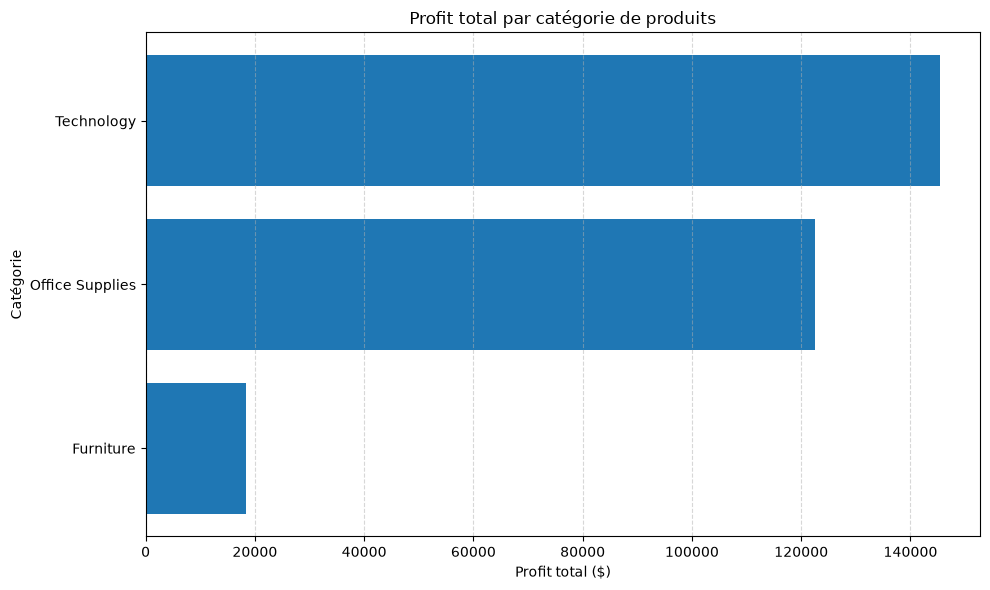

Graphique enregistré : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\reports\profit_par_categorie_produits.png


In [128]:
import matplotlib.pyplot as plt
from pathlib import Path

categories_graphique = performance_categories_produits.sort_values(
    "Profit_total",
    ascending=True
)

plt.figure(figsize=(10, 6))

plt.barh(
    categories_graphique["Category"],
    categories_graphique["Profit_total"]
)

plt.title("Profit total par catégorie de produits")
plt.xlabel("Profit total ($)")
plt.ylabel("Catégorie")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()

# Sauvegarder le graphique
dossier_rapports = Path("../reports")
dossier_rapports.mkdir(parents=True, exist_ok=True)

chemin_graphique = dossier_rapports / "profit_par_categorie_produits.png"

plt.savefig(
    chemin_graphique,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graphique enregistré :", chemin_graphique.resolve())

# Synthèse générale de l'analyse commerciale

# Limites de l'analyse

Cette analyse présente plusieurs limites qu'il convient de prendre en compte lors de l'interprétation des résultats.

### 1. Limites liées au dataset

- Les données couvrent uniquement la période 2014–2017. Elles ne permettent pas de décrire la situation commerciale actuelle.
- Le dataset concerne les ventes d'une entreprise aux États-Unis. Les résultats ne sont pas nécessairement généralisables à d'autres marchés.
- Certaines informations opérationnelles, notamment les coûts logistiques détaillés, les coûts d'acquisition et les charges fixes, ne sont pas disponibles.

### 2. Limites liées à l'interprétation

- Une association entre deux variables ne démontre pas une relation de causalité.
- Les marges négatives observées ne permettent pas, à elles seules, d'identifier les causes exactes des pertes.
- Les valeurs extrêmes ont été conservées, car elles peuvent représenter des transactions commerciales réelles.
- Les performances agrégées des clients et des produits peuvent masquer des différences importantes entre les transactions individuelles.

### 3. Limites méthodologiques

- Les analyses reposent principalement sur des agrégations descriptives avec Pandas.
- Aucune méthode statistique inférentielle ni aucun modèle prédictif n'a été utilisé.
- Les relations entre certaines références produits et leurs identifiants n'ont pas été corrigées en l'absence d'un référentiel produit fiable.

### 4. Perspectives d'amélioration

Pour approfondir cette étude, plusieurs évolutions seraient possibles :

- Intégrer les coûts logistiques et les autres charges opérationnelles.
- Étudier la rentabilité à l'échelle de chaque commande.
- Approfondir l'analyse de la saisonnalité sur une période plus longue.
- Développer des tableaux de bord interactifs.
- Mettre en place des contrôles automatisés de qualité des données.

**Conclusion :** les résultats constituent une base d'analyse descriptive utile pour comprendre les performances commerciales du dataset. Ils doivent toutefois être interprétés en tenant compte des limites des données disponibles et des méthodes employées.

phase 8

In [129]:
from pathlib import Path

dossier_projet = Path("..")

for element in sorted(dossier_projet.iterdir()):
    if element.is_dir():
        print(f"[DOSSIER] {element.name}/")
        for fichier in sorted(element.iterdir()):
            print(f"    {fichier.name}")
    else:
        print(f"[FICHIER] {element.name}")

[FICHIER] .gitignore
[DOSSIER] .venv/
    .gitignore
    etc
    Include
    Lib
    pyvenv.cfg
    Scripts
    share
[DOSSIER] data/
    processed
    raw
[DOSSIER] docs/
    regles_nettoyage.md
[DOSSIER] notebooks/
    01_inspection_initiale.ipynb
[DOSSIER] reports/
    chiffre_affaires_par_categorie.png
    chiffre_affaires_par_region.png
    chiffre_affaires_par_segment.png
    chiffre_affaires_par_sous_categorie.png
    commandes_par_mode_expedition.png
    evolution_chiffre_affaires_annuel.png
    evolution_chiffre_affaires_mensuel.png
    evolution_marge_annuelle.png
    evolution_profit_annuel.png
    marge_beneficiaire_par_remise.png
    profit_par_categorie.png
    profit_par_categorie_produits.png
    profit_par_region.png
    profit_par_segment.png
    profit_par_sous_categorie.png
    top_10_clients_deficitaires.png
    top_10_clients_profit.png
    top_10_produits_chiffre_affaires.png
    top_10_produits_deficitaires.png
    top_10_produits_profit.png
[FICHIER] requiremen

In [130]:
from pathlib import Path

chemin_gitignore = Path("../.gitignore")

if chemin_gitignore.exists():
    print(chemin_gitignore.read_text(encoding="utf-8"))
else:
    print("Le fichier .gitignore n'existe pas.")

# Environnement virtuel Python
.venv/
venv/
env/

# Fichiers Python temporaires
__pycache__/
*.py[cod]

# Fichiers Jupyter temporaires
.ipynb_checkpoints/

# Données brutes
data/raw/

# Fichiers système
.DS_Store
Thumbs.db

# Fichiers temporaires
*.tmp
*.log



In [131]:
from pathlib import Path

contenu_gitignore = """
# Environnement virtuel Python
.venv/
venv/
env/

# Fichiers Python temporaires
__pycache__/
*.py[cod]

# Fichiers Jupyter temporaires
.ipynb_checkpoints/

# Données brutes
data/raw/

# Fichiers système
.DS_Store
Thumbs.db

# Fichiers temporaires
*.tmp
*.log
"""

chemin_gitignore = Path("../.gitignore")

chemin_gitignore.write_text(
    contenu_gitignore.strip() + "\n",
    encoding="utf-8"
)

print("Fichier .gitignore créé :", chemin_gitignore.resolve())

Fichier .gitignore créé : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\.gitignore


In [132]:
from pathlib import Path

chemin_gitignore = Path("../.gitignore")

print(chemin_gitignore.read_text(encoding="utf-8"))

# Environnement virtuel Python
.venv/
venv/
env/

# Fichiers Python temporaires
__pycache__/
*.py[cod]

# Fichiers Jupyter temporaires
.ipynb_checkpoints/

# Données brutes
data/raw/

# Fichiers système
.DS_Store
Thumbs.db

# Fichiers temporaires
*.tmp
*.log



In [133]:
from pathlib import Path

contenu_documentation = """# Documentation des règles de nettoyage

## 1. Présentation

Ce document décrit les anomalies identifiées lors de l'audit du dataset Sample Superstore,
les traitements appliqués et les décisions prises pour préserver l'intégrité des données.

## 2. Règles de nettoyage appliquées

| Anomalie | Traitement | Décision |
|---|---|---|
| Espaces au début et à la fin des noms de produits | Suppression avec strip() | Appliqué |
| Espaces multiples dans les noms de produits | Normalisation des espaces | Appliqué |
| Types incorrects des dates | Conversion en datetime | Appliqué |
| Type incorrect de Postal Code | Conversion en chaîne de caractères | Appliqué |

## 3. Anomalies conservées et documentées

| Anomalie | Décision | Justification |
|---|---|---|
| Doublon métier suspect | Conservation des deux lignes | Absence de preuve suffisante pour supprimer une ligne |
| Product ID associés à plusieurs noms | Conservation | Absence de référentiel produit fiable |
| Product Name associés à plusieurs IDs | Conservation | Plusieurs références peuvent correspondre à des variantes |
| Valeurs extrêmes de Sales et Profit | Conservation | Elles peuvent représenter des transactions commerciales réelles |
| Profits négatifs | Conservation | Ils représentent des pertes commerciales possibles |

## 4. Contrôles après nettoyage

Les contrôles réalisés ont notamment confirmé :

- 9 994 lignes conservées.
- 21 colonnes conservées.
- Aucune valeur manquante.
- Aucun doublon exact.
- Aucune date d'expédition antérieure à la date de commande.
- Aucun identifiant Row ID dupliqué.
- Aucune quantité nulle ou négative.

## 5. Résultat

Le dataset nettoyé a été exporté dans :

`data/processed/superstore_cleaned.csv`

Une relecture du fichier exporté a permis de vérifier la conservation des dimensions,
des colonnes et des valeurs du DataFrame nettoyé.
"""

chemin_documentation = Path("../docs/regles_nettoyage.md")
chemin_documentation.parent.mkdir(parents=True, exist_ok=True)

chemin_documentation.write_text(
    contenu_documentation,
    encoding="utf-8"
)

print("Documentation créée :", chemin_documentation.resolve())

Documentation créée : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\docs\regles_nettoyage.md


In [134]:
from pathlib import Path

chemin_documentation = Path("../docs/regles_nettoyage.md")

contenu = chemin_documentation.read_text(encoding="utf-8")

print(contenu)
print("\nNombre de caractères :", len(contenu))


# Documentation des règles de nettoyage

## 1. Présentation

Ce document décrit les anomalies identifiées lors de l'audit du dataset Sample Superstore,
les traitements appliqués et les décisions prises pour préserver l'intégrité des données.

## 2. Règles de nettoyage appliquées

| Anomalie | Traitement | Décision |
|---|---|---|
| Espaces au début et à la fin des noms de produits | Suppression avec strip() | Appliqué |
| Espaces multiples dans les noms de produits | Normalisation des espaces | Appliqué |
| Types incorrects des dates | Conversion en datetime | Appliqué |
| Type incorrect de Postal Code | Conversion en chaîne de caractères | Appliqué |

## 3. Anomalies conservées et documentées

| Anomalie | Décision | Justification |
|---|---|---|
| Doublon métier suspect | Conservation des deux lignes | Absence de preuve suffisante pour supprimer une ligne |
| Product ID associés à plusieurs noms | Conservation | Absence de référentiel produit fiable |
| Product Name associés à plusie

In [135]:
import json
from pathlib import Path

chemin_notebook = Path("../notebooks/01_inspection_initiale.ipynb")

with open(chemin_notebook, "r", encoding="utf-8") as fichier:
    notebook = json.load(fichier)

cellules = notebook["cells"]

cellules_code_non_executees = []
erreurs_execution = []
titres_markdown = []

for numero, cellule in enumerate(cellules, start=1):

    if cellule["cell_type"] == "code":
        if cellule.get("execution_count") is None:
            cellules_code_non_executees.append(numero)

        for sortie in cellule.get("outputs", []):
            if sortie.get("output_type") == "error":
                erreurs_execution.append({
                    "cellule": numero,
                    "erreur": sortie.get("ename"),
                    "message": sortie.get("evalue")
                })

    elif cellule["cell_type"] == "markdown":
        contenu = "".join(cellule.get("source", []))

        for ligne in contenu.splitlines():
            if ligne.startswith("#"):
                titres_markdown.append(ligne)

print("Nombre total de cellules :", len(cellules))
print("Cellules de code non exécutées :", cellules_code_non_executees)
print("Erreurs d'exécution :", erreurs_execution)

print("\nTitres Markdown :")
for titre in titres_markdown:
    print(titre)

Nombre total de cellules : 159
Cellules de code non exécutées : [139, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159]
Erreurs d'exécution : []

Titres Markdown :
# Projet 01 — Analyse et nettoyage d'un jeu de données de ventes
## 1. Objectif
## 2. Dataset
## 3. Démarche
## 4. Chargement du dataset
## 5. Inspection des types de données
## 6. Audit des valeurs catégorielles
## 7. Audit des dates
### Résultat : répétition de lignes métier
## Phase 5 — Nettoyage des données
## Phase 6 — Validation des données après nettoyage
# Phase 7 — Analyse et visualisation
# Synthèse générale de l'analyse commerciale
# Limites de l'analyse
### 1. Limites liées au dataset
### 2. Limites liées à l'interprétation
### 3. Limites méthodologiques
### 4. Perspectives d'amélioration


In [136]:
for numero in [39, 141, 149, 150, 151, 152, 153, 154, 155, 156, 157]:

    cellule = cellules[numero - 1]

    print(f"\n{'=' * 60}")
    print(f"CELLULE {numero}")
    print("Type :", cellule["cell_type"])
    print("Exécution :", cellule.get("execution_count"))

    contenu = "".join(cellule.get("source", []))
    print(contenu[:1500])

    if cellule["cell_type"] == "code":
        print("Sorties :", cellule.get("outputs", []))


CELLULE 39
Type : code
Exécution : 32
noms_incoherents = (
    df.groupby("Product Name")["Product ID"]
    .nunique()
)

noms_incoherents = noms_incoherents[noms_incoherents > 1]

display(noms_incoherents)
Sorties : [{'data': {'text/plain': ['Product Name\n', '#10- 4 1/8" x 9 1/2" Recycled Envelopes           2\n', 'Avery Non-Stick Binders                           2\n', 'Easy-staple paper                                 8\n', 'Eldon Wave Desk Accessories                       2\n', 'KI Adjustable-Height Table                        2\n', 'Okidata C610n Printer                             2\n', 'Peel & Seel Recycled Catalog Envelopes, Brown     2\n', 'Prang Drawing Pencil Set                          2\n', 'Staple envelope                                   9\n', 'Staple holder                                     3\n', 'Staple magnet                                     2\n', 'Staple remover                                    3\n', 'Staple-based wall hangings                        2\n

In [137]:
import json
from pathlib import Path

chemin_notebook = Path("../notebooks/01_inspection_initiale.ipynb")

with open(chemin_notebook, "r", encoding="utf-8") as fichier:
    notebook = json.load(fichier)

cellules_code = [
    cellule for cellule in notebook["cells"]
    if cellule["cell_type"] == "code"
]

non_executees = [
    numero for numero, cellule in enumerate(cellules_code, start=1)
    if cellule.get("execution_count") is None
    and "".join(cellule.get("source", [])).strip()
]

erreurs = [
    sortie
    for cellule in cellules_code
    for sortie in cellule.get("outputs", [])
    if sortie.get("output_type") == "error"
]

print("Nombre de cellules :", len(notebook["cells"]))
print("Cellules de code :", len(cellules_code))
print("Cellules non exécutées :", len(non_executees))
print("Erreurs enregistrées :", len(erreurs))
print("Notebook :", chemin_notebook.resolve())

Nombre de cellules : 159
Cellules de code : 145
Cellules non exécutées : 1
Erreurs enregistrées : 0
Notebook : D:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis\notebooks\01_inspection_initiale.ipynb


In [138]:
from pathlib import Path

racine = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

elements = [
    "README.md",
    ".gitignore",
    "requirements.txt",
    "docs/regles_nettoyage.md",
    "notebooks/01_inspection_initiale.ipynb",
    "data/processed/superstore_cleaned.csv",
]

for element in elements:
    chemin = racine / element
    print(f"{'OK' if chemin.exists() else 'ABSENT'} : {element}")

graphiques = list((racine / "reports").glob("*.png"))
print(f"\nNombre de graphiques PNG : {len(graphiques)}")

OK : README.md
OK : .gitignore
OK : requirements.txt
OK : docs/regles_nettoyage.md
OK : notebooks/01_inspection_initiale.ipynb
OK : data/processed/superstore_cleaned.csv

Nombre de graphiques PNG : 20


In [140]:
from pathlib import Path

fichier = Path.cwd().parent / "requirements.txt" if Path.cwd().name == "notebooks" else Path.cwd() / "requirements.txt"

contenu = fichier.read_bytes()

if contenu.startswith(b"\xff\xfe") or contenu.startswith(b"\xfe\xff"):
    texte = contenu.decode("utf-16")
else:
    texte = contenu.decode("utf-8-sig")

print(texte)

anyio==4.16.0
argon2-cffi==25.1.0
argon2-cffi-bindings==26.1.0
arrow==1.4.0
asttokens==3.0.2
async-lru==2.4.0
attrs==26.1.0
babel==2.18.0
beautifulsoup4==4.15.0
bleach==6.4.0
certifi==2026.10.23
cffi==2.1.1
charset-normalizer==3.5.2
colorama==0.4.6
comm==0.2.3
contourpy==1.4.0
cycler==0.12.1
debugpy==1.8.22
defusedxml==0.7.1
executing==2.3.0
fastjsonschema==2.22.3
fonttools==4.68.0
fqdn==1.6.0
h11==0.16.0
httpcore==1.0.9
httpx==0.28.1
idna==3.20
ipykernel==7.4.0
ipython==9.18.1
ipython_pygments_lexers==1.1.1
ipywidgets==8.1.9
isoduration==20.11.0
jedi==0.20.1
Jinja2==3.1.6
json5==0.17.3
jsonpointer==3.10
jsonschema==4.26.0
jsonschema-specifications==2025.9.1
jupyter==1.1.1
jupyter-console==6.6.3
jupyter-events==0.12.1
jupyter-lsp==2.3.1
jupyter_builder==1.2.4
jupyter_client==8.10.0
jupyter_core==5.9.1
jupyter_server==2.21.1
jupyter_server_terminals==0.5.4
jupyterlab==4.6.6
jupyterlab_pygments==0.3.0
jupyterlab_server==2.28.1
jupyterlab_widgets==3.0.17
kiwisolver==1.5.1
lark==1.3.1
Mark

In [141]:
from pathlib import Path

racine = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

requirements = """pandas==3.1.1
numpy==2.5.4
matplotlib==3.11.2
notebook==7.6.5
ipykernel==7.4.0
"""

fichier = racine / "requirements.txt"
fichier.write_text(requirements, encoding="utf-8")

print("requirements.txt mis à jour.")
print(fichier.read_text(encoding="utf-8"))

requirements.txt mis à jour.
pandas==3.1.1
numpy==2.5.4
matplotlib==3.11.2
notebook==7.6.5
ipykernel==7.4.0



In [143]:
from pathlib import Path

racine = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

print("Racine du projet :", racine)
print("Dossier .git présent :", (racine / ".git").exists())
print("Dossier .gitignore présent :", (racine / ".gitignore").exists())

Racine du projet : d:\CODE-PROGRAMATION\PROJETS IA\sales-data-analysis
Dossier .git présent : False
Dossier .gitignore présent : True
